In [1]:
%%writefile /kaggle/working/asr_worker.py
import sys, os, pickle, time, numpy as np, pandas as pd, soundfile as sf, torch
from transformers import WhisperProcessor, WhisperForConditionalGeneration

gpu, nshards = int(sys.argv[1]), int(sys.argv[2])
DATA = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT = f'/kaggle/working/asr_{gpu}.pkl'
M = 'openai/whisper-large-v3'
FILES_PER_BATCH = 6

tr = pd.read_csv(f'{DATA}/train.csv'); tr['split'] = 'train'
te = pd.read_csv(f'{DATA}/test.csv');  te['split'] = 'test'
df = pd.concat([tr, te], ignore_index=True).iloc[gpu::nshards]
items = list(zip(df['split'], df['filename']))

dev = f'cuda:{gpu}'
proc = WhisperProcessor.from_pretrained(M)
model = WhisperForConditionalGeneration.from_pretrained(M, dtype=torch.float16).to(dev).eval()

res = pickle.load(open(OUT, 'rb')) if os.path.exists(OUT) else {}
todo = [k for k in items if k not in res]
print(f'GPU{gpu}: {len(todo)} files to do', flush=True)

CH = 30 * 16000
t0 = time.time()
for b in range(0, len(todo), FILES_PER_BATCH):
    batch = todo[b:b + FILES_PER_BATCH]
    chunks, owner, meta = [], [], {}
    for k in batch:
        x, sr = sf.read(f'{DATA}/{k[0]}/{k[1]}', dtype='float32')
        if x.ndim > 1: x = x.mean(1)
        assert sr == 16000, sr
        meta[k] = {'dur': len(x) / sr, 'rms': float(np.sqrt((x ** 2).mean()))}
        for s in range(0, len(x), CH):
            c = x[s:s + CH]
            if len(c) >= 16000:
                chunks.append(c); owner.append(k)
    texts = {k: [] for k in batch}
    if chunks:
        feats = proc.feature_extractor(chunks, sampling_rate=16000, return_tensors='pt').input_features
        feats = feats.to(dev, torch.float16)
        with torch.no_grad():
            ids = model.generate(feats, language='en', task='transcribe',
                                 num_beams=1, do_sample=False, max_new_tokens=200)
        for k, t in zip(owner, proc.batch_decode(ids, skip_special_tokens=True)):
            texts[k].append(t.strip())
    for k in batch:
        res[k] = {'text': ' '.join(texts[k]).strip(), **meta[k]}
    if (b // FILES_PER_BATCH) % 5 == 0 or b + FILES_PER_BATCH >= len(todo):
        pickle.dump(res, open(OUT, 'wb'))
        done = min(b + FILES_PER_BATCH, len(todo))
        print(f'GPU{gpu}: {done}/{len(todo)}  {(time.time()-t0)/done:.2f} s/file', flush=True)
pickle.dump(res, open(OUT, 'wb'))
print(f'GPU{gpu}: FINISHED', flush=True)

Writing /kaggle/working/asr_worker.py


In [2]:
import subprocess
procs = [subprocess.Popen(['python', '/kaggle/working/asr_worker.py', str(g), '2'],
                          stdout=open(f'/kaggle/working/log{g}.txt', 'w'),
                          stderr=subprocess.STDOUT) for g in (0, 1)]
print("launched")

launched


In [3]:
import subprocess
for g in (0, 1):
    print(subprocess.run(['tail', '-n', '3', f'/kaggle/working/log{g}.txt'],
                         capture_output=True, text=True).stdout)
print(subprocess.run(['nvidia-smi', '--query-gpu=memory.used,utilization.gpu', '--format=csv'],
                     capture_output=True, text=True).stdout)



memory.used [MiB], utilization.gpu [%]
0 MiB, 0 %
0 MiB, 0 %



In [4]:
import subprocess, os
for g, p in enumerate(procs):
    print(f"worker {g}: poll() =", p.poll(), "(None = still running, number = exited with that code)")
    lp = f'/kaggle/working/log{g}.txt'
    print("  log size:", os.path.getsize(lp) if os.path.exists(lp) else "missing")
    print("  log content:\n", open(lp).read()[-1500:] if os.path.exists(lp) else "")
print(subprocess.run('ps aux | grep asr_worker | grep -v grep', shell=True, capture_output=True, text=True).stdout)
print(subprocess.run('ls -la /kaggle/working/', shell=True, capture_output=True, text=True).stdout)

worker 0: poll() = None (None = still running, number = exited with that code)
  log size: 0
  log content:
 
worker 1: poll() = None (None = still running, number = exited with that code)
  log size: 0
  log content:
 
root         118 51.2  1.8 5031656 594916 ?      Dl   06:30   0:03 python3 /kaggle/working/asr_worker.py 0 2
root         119 51.1  1.8 5031608 595532 ?      Rl   06:30   0:03 python3 /kaggle/working/asr_worker.py 1 2

total 16
drwxr-xr-x 3 root root 4096 Oct 17 06:30 .
drwxr-xr-x 5 root root 4096 Oct 17 06:29 ..
-rw-r--r-- 1 root root 2399 Oct 17 06:30 asr_worker.py
-rw-r--r-- 1 root root    0 Oct 17 06:30 log0.txt
-rw-r--r-- 1 root root    0 Oct 17 06:30 log1.txt
drwxr-xr-x 2 root root 4096 Oct 17 06:29 .virtual_documents



In [5]:
import subprocess
for g in (0, 1):
    print(subprocess.run(['tail', '-n', '3', f'/kaggle/working/log{g}.txt'],
                         capture_output=True, text=True).stdout)
print(subprocess.run(['nvidia-smi', '--query-gpu=memory.used,utilization.gpu', '--format=csv'],
                     capture_output=True, text=True).stdout)



memory.used [MiB], utilization.gpu [%]
0 MiB, 0 %
0 MiB, 0 %



In [6]:
import subprocess
for g in (0, 1):
    out = subprocess.run(f"grep -E 'GPU{g}:' /kaggle/working/log{g}.txt | tail -n 2",
                         shell=True, capture_output=True, text=True).stdout
    print(out)
print(subprocess.run(['nvidia-smi', '--query-gpu=memory.used,utilization.gpu', '--format=csv'],
                     capture_output=True, text=True).stdout)



memory.used [MiB], utilization.gpu [%]
0 MiB, 0 %
0 MiB, 0 %



In [7]:
import subprocess
for g in (0, 1):
    print(subprocess.run(f"grep -E 'GPU{g}:' /kaggle/working/log{g}.txt | tail -n 1",
                         shell=True, capture_output=True, text=True).stdout)

GPU0: FINISHED

GPU1: FINISHED



In [8]:
import subprocess
for g in (0, 1):
    print(subprocess.run(f"grep -E 'GPU{g}:' /kaggle/working/log{g}.txt | tail -n 1",
                         shell=True, capture_output=True, text=True).stdout)

GPU0: FINISHED

GPU1: FINISHED



In [9]:
import pickle, pandas as pd, numpy as np
DATA = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'

res = {}
for g in (0, 1):
    res.update(pickle.load(open(f'/kaggle/working/asr_{g}.pkl', 'rb')))
pickle.dump(res, open('/kaggle/working/asr_all.pkl', 'wb'))

tr = pd.read_csv(f'{DATA}/train.csv'); tr['split'] = 'train'
te = pd.read_csv(f'{DATA}/test.csv');  te['split'] = 'test'
alldf = pd.concat([tr, te], ignore_index=True)
assert len(res) == len(alldf) == 985, (len(res), len(alldf))

alldf['text']    = [res[(s, f)]['text'] for s, f in zip(alldf.split, alldf.filename)]
alldf['n_words'] = alldf.text.str.split().str.len()
alldf['rms']     = [res[(s, f)]['rms'] for s, f in zip(alldf.split, alldf.filename)]
alldf['dur']     = [res[(s, f)]['dur'] for s, f in zip(alldf.split, alldf.filename)]
alldf.to_pickle('/kaggle/working/alldf.pkl')

t = alldf[alldf.split == 'train']
print(t.groupby('label')[['n_words', 'rms', 'dur']].mean().round(3))
print("\nempty transcripts:", (alldf.n_words == 0).sum(), "| train corr(n_words,label):",
      round(t[['n_words', 'label']].corr().iloc[0, 1], 3))

pd.set_option('display.max_colwidth', 220)
print("\n--- LABEL 0 ---")
print(t[t.label == 0][['filename', 'n_words', 'text']].head(6).to_string())
print("\n--- LABEL 2 ---")
print(t[t.label == 2][['filename', 'n_words', 'text']].head(3).to_string())
print("\n--- LABEL 5 ---")
print(t[t.label == 5][['filename', 'n_words', 'text']].head(3).to_string())

       n_words    rms     dur
label                        
0.0     76.622  0.122  57.864
1.0    125.000  0.031  45.060
1.5     60.333  0.047  60.070
2.0     84.049  0.051  53.561
2.5     87.038  0.056  55.126
3.0     93.299  0.060  55.726
3.5     95.484  0.058  56.649
4.0     95.508  0.058  52.810
4.5    102.846  0.058  58.392
5.0    116.812  0.061  58.681

empty transcripts: 0 | train corr(n_words,label): 0.377

--- LABEL 0 ---
          filename  n_words                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

In [10]:
import pandas as pd, numpy as np, re
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import pearsonr

df = pd.read_pickle('/kaggle/working/alldf.pkl')
t = df[df.split == 'train'].reset_index(drop=True)

# Is the label-0 loudness a real cluster or a few outliers?
print(t.assign(g=np.where(t.label == 0, 'label0', 'rest')).groupby('g').rms.describe().round(3))

def feats(r):
    w = re.findall(r"[A-Za-z']+", r.text.lower()); n = max(len(w), 1)
    sents = [s for s in re.split(r'[.!?]+', r.text) if s.strip()]
    return dict(n_words=len(w), wps=len(w) / r.dur, ttr=len(set(w)) / n,
                n_sent=len(sents), avg_sent=len(w) / max(len(sents), 1),
                rep=sum(w[i] == w[i-1] for i in range(1, len(w))) / n,
                fill=sum(x in {'um', 'uh', 'er', 'erm', 'hmm'} for x in w) / n,
                rms=r.rms, dur=r.dur)

X = pd.DataFrame([feats(r) for r in t.itertuples()]); y = t.label.values
strat = np.where(y == 0, 0, np.digitize(y, [2.25, 3.25, 4.25]) + 1)
oof = np.zeros(len(t))
for tri, vai in StratifiedKFold(5, shuffle=True, random_state=0).split(X, strat):
    m = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)
    oof[vai] = m.fit(X.iloc[tri], y[tri]).predict(X.iloc[vai])
oof = np.clip(oof, 0, 5)
print("quick baseline  OOF RMSE:", round(np.sqrt(((oof - y) ** 2).mean()), 4),
      "| Pearson:", round(pearsonr(oof, y)[0], 4))
print("label-0 files: mean OOF pred", round(oof[y == 0].mean(), 2))

        count   mean    std    min    25%    50%    75%    max
g                                                             
label0   37.0  0.122  0.023  0.067  0.108  0.126  0.137  0.169
rest    732.0  0.058  0.023  0.004  0.044  0.059  0.073  0.186
quick baseline  OOF RMSE: 0.9176 | Pearson: 0.672
label-0 files: mean OOF pred 1.14


In [11]:
%%writefile /kaggle/working/emb_worker.py
import sys, os, pickle, numpy as np, pandas as pd, soundfile as sf, torch
from transformers import AutoFeatureExtractor, WavLMModel
gpu, n = int(sys.argv[1]), int(sys.argv[2])
DATA = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
tr = pd.read_csv(f'{DATA}/train.csv'); tr['split'] = 'train'
te = pd.read_csv(f'{DATA}/test.csv');  te['split'] = 'test'
items = list(zip(*[pd.concat([tr, te], ignore_index=True).iloc[gpu::n][c] for c in ('split', 'filename')]))
dev = f'cuda:{gpu}'
fe = AutoFeatureExtractor.from_pretrained('microsoft/wavlm-large')
m = WavLMModel.from_pretrained('microsoft/wavlm-large').half().to(dev).eval()
out = {}
for i, k in enumerate(items):
    x, sr = sf.read(f'{DATA}/{k[0]}/{k[1]}', dtype='float32')
    if x.ndim > 1: x = x.mean(1)
    inp = fe(x, sampling_rate=16000, return_tensors='pt').input_values.to(dev).half()
    with torch.no_grad():
        hs = torch.stack(m(inp, output_hidden_states=True).hidden_states)[:, 0].float()  # (25, T, 1024)
    out[k] = np.concatenate([hs.mean(1).cpu().numpy(), hs.std(1).cpu().numpy()]).astype(np.float16)
    if i % 50 == 0: print(f'GPU{gpu}: {i}/{len(items)}', flush=True)
pickle.dump(out, open(f'/kaggle/working/emb_{gpu}.pkl', 'wb'))
print(f'GPU{gpu}: FINISHED', flush=True)

Writing /kaggle/working/emb_worker.py


In [12]:
import subprocess
procs = [subprocess.Popen(['python', '/kaggle/working/emb_worker.py', str(g), '2'],
                          stdout=open(f'/kaggle/working/elog{g}.txt', 'w'),
                          stderr=subprocess.STDOUT) for g in (0, 1)]
print("launched")

launched


In [13]:
import pandas as pd, numpy as np
from sklearn.metrics import roc_auc_score

df = pd.read_pickle('/kaggle/working/alldf.pkl')
t  = df[df.split == 'train'].reset_index(drop=True)
te = df[df.split == 'test']
is0 = (t.label == 0).values

print("AUC of rms for detecting label 0:", round(roc_auc_score(is0, t.rms), 4))
for th in [0.07, 0.08, 0.09, 0.10, 0.11]:
    flag = (t.rms > th).values
    print(f"rms>{th}: flagged {flag.sum():3d} | label0 caught {(flag & is0).sum():2d}/37 "
          f"| false alarms {(flag & ~is0).sum():3d}")

flag = (t.rms > 0.09).values
print("\nLabels of the non-zero files flagged loud (rms>0.09):")
print(t[flag & ~is0].label.value_counts().sort_index())
print("\nTest files with rms>0.09:", (te.rms > 0.09).sum(), "of", len(te))

t['id'] = t.filename.str.extract(r'(\d+)').astype(int)
print("\nFilename-number range, diagnostic only (not a feature):")
print(t.groupby(is0).id.describe().round(0))

AUC of rms for detecting label 0: 0.9724
rms>0.07: flagged 251 | label0 caught 36/37 | false alarms 215
rms>0.08: flagged 133 | label0 caught 36/37 | false alarms  97
rms>0.09: flagged  81 | label0 caught 34/37 | false alarms  47
rms>0.1: flagged  52 | label0 caught 29/37 | false alarms  23
rms>0.11: flagged  37 | label0 caught 26/37 | false alarms  11

Labels of the non-zero files flagged loud (rms>0.09):
label
2.0     3
2.5     8
3.0    17
3.5     6
4.0     8
4.5     1
5.0     4
Name: count, dtype: int64

Test files with rms>0.09: 16 of 216

Filename-number range, diagnostic only (not a feature):
       count    mean    std     min     25%     50%     75%     max
False  732.0   385.0  229.0     0.0   184.0   380.0   583.0   784.0
True    37.0  5055.0   11.0  5037.0  5046.0  5055.0  5064.0  5073.0


In [15]:
import subprocess
for g in (0, 1):
    print(subprocess.run(f"grep -E 'GPU{g}:' /kaggle/working/elog{g}.txt | tail -n 1",
                         shell=True, capture_output=True, text=True).stdout)

GPU0: FINISHED

GPU1: FINISHED



In [16]:
import pandas as pd, numpy as np
df = pd.read_pickle('/kaggle/working/alldf.pkl')
te = df[df.split == 'test'].copy()
te['id'] = te.filename.str.extract(r'(\d+)').astype(int)
print(te.id.describe().round(0))
print("test ids >= 5000:", (te.id >= 5000).sum(), "of", len(te))
print("test rms describe:\n", te.rms.describe().round(3))

t = df[df.split == 'train']
nz = t[t.label > 0]
print("\nMean-predictor RMSE excluding label 0:",
      round(np.sqrt(((nz.label - nz.label.mean())**2).mean()), 4))

count    216.0
mean     108.0
std       62.0
min        0.0
25%       54.0
50%      108.0
75%      161.0
max      215.0
Name: id, dtype: float64
test ids >= 5000: 0 of 216
test rms describe:
 count    216.000
mean       0.047
std        0.032
min        0.002
25%        0.018
50%        0.050
75%        0.069
max        0.193
Name: rms, dtype: float64

Mean-predictor RMSE excluding label 0: 1.0137


In [17]:
import subprocess
for g in (0, 1):
    print(subprocess.run(f"grep -E 'GPU{g}:' /kaggle/working/elog{g}.txt | tail -n 1",
                         shell=True, capture_output=True, text=True).stdout)

GPU0: FINISHED

GPU1: FINISHED



In [18]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

emb = {}
for g in (0, 1): emb.update(pickle.load(open(f'/kaggle/working/emb_{g}.pkl', 'rb')))
assert len(emb) == 985, len(emb)

df = pd.read_pickle('/kaggle/working/alldf.pkl')
t = df[(df.split == 'train') & (df.label > 0)].reset_index(drop=True)   # drop the 37 label-0 files
E = np.stack([emb[('train', f)] for f in t.filename]).astype(np.float32)  # (732, 50, 1024)
y = t.label.values
strat = np.digitize(y, [2.25, 3.25, 4.25])
folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(E, strat))
print("n =", len(y), "| mean-predictor RMSE:", round(y.std(), 4))

rows = []
for L in range(25):
    X = np.concatenate([E[:, L], E[:, 25 + L]], 1)
    oof = np.zeros(len(y))
    for tri, vai in folds:
        m = make_pipeline(StandardScaler(), RidgeCV(alphas=[300, 1000, 3000, 10000, 30000]))
        oof[vai] = m.fit(X[tri], y[tri]).predict(X[vai])
    oof = np.clip(oof, 0, 5)
    rows.append(dict(layer=L, rmse=np.sqrt(((oof - y)**2).mean()), pearson=pearsonr(oof, y)[0]))
res = pd.DataFrame(rows).round(4)
print(res.to_string(index=False))
print("\nBest 5 by RMSE:\n", res.sort_values('rmse').head(5).to_string(index=False))

n = 732 | mean-predictor RMSE: 1.0137
 layer   rmse  pearson
     0 0.6785   0.7429
     1 0.6815   0.7407
     2 0.6412   0.7747
     3 0.6546   0.7643
     4 0.6599   0.7592
     5 0.6357   0.7790
     6 0.6363   0.7785
     7 0.6255   0.7870
     8 0.5881   0.8146
     9 0.5751   0.8236
    10 0.5743   0.8244
    11 0.5604   0.8333
    12 0.5649   0.8305
    13 0.5498   0.8402
    14 0.5488   0.8409
    15 0.5602   0.8335
    16 0.5492   0.8409
    17 0.5516   0.8395
    18 0.5510   0.8398
    19 0.5570   0.8359
    20 0.5562   0.8365
    21 0.5502   0.8403
    22 0.5657   0.8299
    23 0.5838   0.8175
    24 0.5801   0.8201

Best 5 by RMSE:
  layer   rmse  pearson
    14 0.5488   0.8409
    16 0.5492   0.8409
    13 0.5498   0.8402
    21 0.5502   0.8403
    18 0.5510   0.8398


In [19]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import RidgeCV
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

emb = {}
for g in (0, 1): emb.update(pickle.load(open(f'/kaggle/working/emb_{g}.pkl', 'rb')))
df = pd.read_pickle('/kaggle/working/alldf.pkl')
t = df[(df.split == 'train') & (df.label > 0)].reset_index(drop=True)
E = np.stack([emb[('train', f)] for f in t.filename]).astype(np.float32)
y = t.label.values
folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(E, np.digitize(y, [2.25, 3.25, 4.25])))

def feat(layers):   # average mean-pool and std-pool over a set of layers
    return np.concatenate([E[:, layers].mean(1), E[:, [25 + l for l in layers]].mean(1)], 1)

def cv(make, X):
    oof = np.zeros(len(y))
    for tri, vai in folds:
        oof[vai] = make().fit(X[tri], y[tri]).predict(X[vai])
    oof = np.clip(oof, 0, 5)
    return oof, np.sqrt(((oof - y) ** 2).mean()), pearsonr(oof, y)[0]

ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=[1000, 3000, 10000, 30000]))
svr = lambda C: (lambda: make_pipeline(StandardScaler(), SVR(C=C, epsilon=0.2, gamma='scale')))

oofs = {}
for name, X, mk in [
    ('ridge avg L9-21',   feat(list(range(9, 22))),  ridge),
    ('ridge avg L13-21',  feat(list(range(13, 22))), ridge),
    ('svr C=3 avg L9-21', feat(list(range(9, 22))),  svr(3)),
    ('svr C=10 avg L9-21',feat(list(range(9, 22))),  svr(10)),
    ('ridge concat L8,14,18,21', np.concatenate([feat([l]) for l in (8, 14, 18, 21)], 1), ridge)]:
    oofs[name], r, p = cv(mk, X)
    print(f"{name:28s} RMSE {r:.4f}  Pearson {p:.4f}")
pickle.dump(oofs, open('/kaggle/working/oof_audio.pkl', 'wb'))

ridge avg L9-21              RMSE 0.5489  Pearson 0.8415
ridge avg L13-21             RMSE 0.5492  Pearson 0.8411
svr C=3 avg L9-21            RMSE 0.5444  Pearson 0.8489
svr C=10 avg L9-21           RMSE 0.5439  Pearson 0.8493
ridge concat L8,14,18,21     RMSE 0.5268  Pearson 0.8545


In [20]:
import numpy as np, pandas as pd, torch
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

df = pd.read_pickle('/kaggle/working/alldf.pkl')
name = 'intfloat/e5-large-v2'
tok = AutoTokenizer.from_pretrained(name)
mdl = AutoModel.from_pretrained(name, dtype=torch.float16).to('cuda:0').eval()

texts = ['query: ' + s for s in df.text]
out = []
for i in range(0, len(texts), 16):
    b = tok(texts[i:i+16], padding=True, truncation=True, max_length=256, return_tensors='pt').to('cuda:0')
    with torch.no_grad():
        h = mdl(**b).last_hidden_state.float()
    m = b['attention_mask'].unsqueeze(-1).float()
    out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
T = np.concatenate(out); np.save('/kaggle/working/text_emb_e5.npy', T)
del mdl; torch.cuda.empty_cache()

tr = (df.split == 'train') & (df.label > 0)
X, y = T[tr.values], df.label[tr].values
folds = StratifiedKFold(5, shuffle=True, random_state=0).split(X, np.digitize(y, [2.25, 3.25, 4.25]))
oof = np.zeros(len(y))
for a, b in folds:
    oof[b] = make_pipeline(StandardScaler(), RidgeCV(alphas=[100, 300, 1000, 3000, 10000])).fit(X[a], y[a]).predict(X[b])
oof = np.clip(oof, 0, 5)
print("text-only e5 ridge  RMSE", round(np.sqrt(((oof - y) ** 2).mean()), 4), " Pearson", round(pearsonr(oof, y)[0], 4))

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/314 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

text-only e5 ridge  RMSE 0.7309  Pearson 0.6944


In [22]:
import numpy as np, pandas as pd, torch, re
from transformers import AutoTokenizer, AutoModelForCausalLM

df = pd.read_pickle('/kaggle/working/alldf.pkl')
tok = AutoTokenizer.from_pretrained('gpt2-medium')
lm = AutoModelForCausalLM.from_pretrained('gpt2-medium', dtype=torch.float16).to('cuda:0').eval()

rows = []
for s, dur in zip(df.text, df.dur):
    # --- LM surprisal: grammatical, fluent text has lower per-token loss ---
    ids = tok(tok.bos_token + s, return_tensors='pt', truncation=True, max_length=512).input_ids.to('cuda:0')
    with torch.no_grad():
        lg = lm(ids).logits.float()
    nll = torch.nn.functional.cross_entropy(lg[0, :-1], ids[0, 1:], reduction='none').cpu().numpy()
    # --- handcrafted text features ---
    w = re.findall(r"[A-Za-z']+", s.lower()); n = max(len(w), 1)
    sents = [x.strip() for x in re.split(r'[.!?]+', s) if x.strip()]
    rows.append(dict(
        nll_mean=nll.mean(), nll_med=np.median(nll), nll_std=nll.std(),
        nll_p90=np.percentile(nll, 90), frac_hi=(nll > 6).mean(), n_tok=len(nll),
        n_words=len(w), wps=len(w) / dur, ttr=len(set(w)) / n, uniq=len(set(w)),
        n_sent=len(sents), avg_sent=len(w) / max(len(sents), 1),
        max_sent=max([len(x.split()) for x in sents], default=0),
        avg_wlen=np.mean([len(x) for x in w]) if w else 0,
        rep=sum(w[i] == w[i-1] for i in range(1, len(w))) / n,
        fill=sum(x in {'um', 'uh', 'er', 'erm', 'hmm'} for x in w) / n,
        no_punct=float(len(re.findall(r'[.,!?]', s)) < 3),
        dur=dur))
F = pd.DataFrame(rows)
F.to_pickle('/kaggle/working/feats.pkl')
del lm; torch.cuda.empty_cache()
print(F.shape); print(F.describe().T[['mean', 'std']].round(3))

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

(985, 18)
             mean     std
nll_mean    3.468   0.577
nll_med     2.874   0.632
nll_std     2.698   0.349
nll_p90     7.126   1.064
frac_hi     0.171   0.066
n_tok     107.451  31.566
n_words    95.283  27.259
wps         1.771   0.464
ttr         0.616   0.095
uniq       57.331  14.898
n_sent      5.378   2.900
avg_sent   25.800  24.197
max_sent   40.725  24.925
avg_wlen    4.242   0.417
rep         0.003   0.008
fill        0.002   0.008
no_punct    0.146   0.353
dur        54.240   8.480


In [23]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

emb = {}
for g in (0, 1): emb.update(pickle.load(open(f'/kaggle/working/emb_{g}.pkl', 'rb')))
df = pd.read_pickle('/kaggle/working/alldf.pkl')
F  = pd.read_pickle('/kaggle/working/feats.pkl').values
T  = np.load('/kaggle/working/text_emb_e5.npy')
E  = np.stack([emb[(s, f)] for s, f in zip(df.split, df.filename)]).astype(np.float32)  # (985, 50, 1024)

def lay(layers):
    return np.concatenate([E[:, layers].mean(1), E[:, [25 + l for l in layers]].mean(1)], 1)
XA_cat = np.concatenate([lay([l]) for l in (8, 14, 18, 21)], 1)
XA_avg = lay(list(range(9, 22)))
XAT    = np.concatenate([XA_cat, T], 1)

tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
te_idx = np.where((df.split == 'test').values)[0]
y = df.label.values[tr_idx]
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))

ridge = lambda a=(1000, 3000, 10000, 30000): (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=list(a))))
svr   = lambda C: (lambda: make_pipeline(StandardScaler(), SVR(C=C, epsilon=0.2)))
hgb   = lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.04, max_iter=300, random_state=0)

models = {
    'ridge_audio_cat': (ridge(),                    XA_cat),
    'svr_audio_cat':   (svr(10),                    XA_cat),
    'svr_audio_avg':   (svr(10),                    XA_avg),
    'ridge_e5':        (ridge((100, 300, 1000, 3000, 10000)), T),
    'ridge_audio+e5':  (ridge((3000, 10000, 30000, 100000)),  XAT),
    'hgb_text_feats':  (hgb,                        F),
}

rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())
OOF, ALL = {}, {}
for name, (mk, X) in models.items():
    oof = np.zeros(len(y))
    for a, b in folds:
        oof[b] = mk().fit(X[tr_idx[a]], y[a]).predict(X[tr_idx[b]])
    OOF[name] = np.clip(oof, 1, 5)
    ALL[name] = np.clip(mk().fit(X[tr_idx], y).predict(X), 1, 5)   # full-fit predictions for all 985 rows
    print(f"{name:16s} OOF RMSE {rmse(OOF[name], y):.4f}  Pearson {pearsonr(OOF[name], y)[0]:.4f}")

names = list(models)
O = np.column_stack([OOF[n] for n in names]); P = np.column_stack([ALL[n] for n in names])
meta = LinearRegression(positive=True)
cvp = np.clip(cross_val_predict(meta, O, y, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)
print(f"\nSTACK (meta-CV)   RMSE {rmse(cvp, y):.4f}  Pearson {pearsonr(cvp, y)[0]:.4f}")
print("simple mean of all RMSE", round(rmse(O.mean(1), y), 4))
meta.fit(O, y)
print("blend weights:", dict(zip(names, meta.coef_.round(3))), "| intercept", round(meta.intercept_, 3))

final = np.clip(meta.predict(P), 1, 5)
# ---- compulsory training RMSE (in-sample fit of the full pipeline) ----
tr_all = np.where((df.split == 'train').values)[0]; yall = df.label.values[tr_all]
nz = yall > 0
print(f"\nTRAIN RMSE, 732 non-zero files: {rmse(final[tr_all][nz], yall[nz]):.4f}")
print(f"TRAIN RMSE, all 769 files:      {rmse(final[tr_all], yall):.4f}  (the 37 label-0 files were excluded from training)")

sub = pd.DataFrame({'filename': df.filename.values[te_idx], 'label': final[te_idx]})
sub.to_csv('/kaggle/working/submission.csv', index=False)
chk = pd.read_csv('/kaggle/working/submission.csv')
print(chk.shape, chk.filename.nunique(), chk.label.isna().sum(), chk.label.describe().round(3).to_dict())
pickle.dump(dict(OOF=OOF, ALL=ALL, y=y, names=names), open('/kaggle/working/stack.pkl', 'wb'))

ridge_audio_cat  OOF RMSE 0.5200  Pearson 0.8585
svr_audio_cat    OOF RMSE 0.5428  Pearson 0.8518
svr_audio_avg    OOF RMSE 0.5516  Pearson 0.8445
ridge_e5         OOF RMSE 0.7249  Pearson 0.7010
ridge_audio+e5   OOF RMSE 0.5193  Pearson 0.8597
hgb_text_feats   OOF RMSE 0.7504  Pearson 0.6736

STACK (meta-CV)   RMSE 0.5017  Pearson 0.8691
simple mean of all RMSE 0.5337
blend weights: {'ridge_audio_cat': np.float64(0.499), 'svr_audio_cat': np.float64(0.415), 'svr_audio_avg': np.float64(0.0), 'ridge_e5': np.float64(0.174), 'ridge_audio+e5': np.float64(0.0), 'hgb_text_feats': np.float64(0.109)} | intercept -0.679

TRAIN RMSE, 732 non-zero files: 0.1694
TRAIN RMSE, all 769 files:      0.5962  (the 37 label-0 files were excluded from training)
(216, 2) 216 0 {'count': 216.0, 'mean': 3.288, 'std': 0.839, 'min': 1.677, '25%': 2.686, '50%': 3.202, '75%': 3.76, 'max': 5.0}


In [24]:
%%writefile /kaggle/working/wenc_worker.py
import sys, pickle, numpy as np, pandas as pd, soundfile as sf, torch
from transformers import WhisperFeatureExtractor, WhisperModel
gpu, n = int(sys.argv[1]), int(sys.argv[2])
DATA = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
tr = pd.read_csv(f'{DATA}/train.csv'); tr['split'] = 'train'
te = pd.read_csv(f'{DATA}/test.csv');  te['split'] = 'test'
sub = pd.concat([tr, te], ignore_index=True).iloc[gpu::n]
items = list(zip(sub['split'], sub['filename']))
dev = f'cuda:{gpu}'
fe = WhisperFeatureExtractor.from_pretrained('openai/whisper-large-v3')
enc = WhisperModel.from_pretrained('openai/whisper-large-v3', dtype=torch.float16).encoder.to(dev).eval()
CH, out = 30 * 16000, {}
for i, k in enumerate(items):
    x, sr = sf.read(f'{DATA}/{k[0]}/{k[1]}', dtype='float32')
    if x.ndim > 1: x = x.mean(1)
    chunks = [x[s:s + CH] for s in range(0, len(x), CH) if len(x[s:s + CH]) >= 16000]
    f = fe(chunks, sampling_rate=16000, return_tensors='pt').input_features.to(dev, torch.float16)
    with torch.no_grad():
        hs = torch.stack(enc(f, output_hidden_states=True).hidden_states).float()  # (33, nchunk, 1500, 1280)
    parts = [hs[:, j, :min(1500, int(np.ceil(len(c) / 320)))] for j, c in enumerate(chunks)]
    v = torch.cat(parts, 1)                                                        # (33, frames, 1280)
    out[k] = np.concatenate([v.mean(1).cpu().numpy(), v.std(1).cpu().numpy()]).astype(np.float16)  # (66, 1280)
    if i % 50 == 0: print(f'GPU{gpu}: {i}/{len(items)}', flush=True)
pickle.dump(out, open(f'/kaggle/working/wenc_{gpu}.pkl', 'wb'))
print(f'GPU{gpu}: FINISHED', flush=True)

Writing /kaggle/working/wenc_worker.py


In [25]:
import subprocess
procs = [subprocess.Popen(['python', '/kaggle/working/wenc_worker.py', str(g), '2'],
                          stdout=open(f'/kaggle/working/wlog{g}.txt', 'w'),
                          stderr=subprocess.STDOUT) for g in (0, 1)]
print("launched")

launched


In [28]:
import subprocess
for g in (0, 1):
    print(subprocess.run(f"grep -E 'GPU{g}:' /kaggle/working/wlog{g}.txt | tail -n 1",
                         shell=True, capture_output=True, text=True).stdout)

GPU0: FINISHED

GPU1: FINISHED



In [29]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

W = {}
for g in (0, 1): W.update(pickle.load(open(f'/kaggle/working/wenc_{g}.pkl', 'rb')))
assert len(W) == 985, len(W)

df = pd.read_pickle('/kaggle/working/alldf.pkl')
t = df[(df.split == 'train') & (df.label > 0)].reset_index(drop=True)
E = np.stack([W[('train', f)] for f in t.filename]).astype(np.float32)   # (732, 66, 1280)
y = t.label.values
folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(E, np.digitize(y, [2.25, 3.25, 4.25])))

rows = []
for L in range(33):
    X = np.concatenate([E[:, L], E[:, 33 + L]], 1)          # mean + std of layer L
    oof = np.zeros(len(y))
    for a, b in folds:
        m = make_pipeline(StandardScaler(), RidgeCV(alphas=[1000, 3000, 10000, 30000, 100000]))
        oof[b] = m.fit(X[a], y[a]).predict(X[b])
    oof = np.clip(oof, 1, 5)
    rows.append(dict(layer=L, rmse=np.sqrt(((oof - y) ** 2).mean()), pearson=pearsonr(oof, y)[0]))
res = pd.DataFrame(rows).round(4)
print(res.to_string(index=False))
print("\nBest 6 by RMSE:\n", res.sort_values('rmse').head(6).to_string(index=False))

 layer   rmse  pearson
     0 0.8282   0.5767
     1 0.7488   0.6748
     2 0.7239   0.7013
     3 0.6913   0.7334
     4 0.6810   0.7427
     5 0.6757   0.7477
     6 0.6650   0.7562
     7 0.6682   0.7534
     8 0.6614   0.7597
     9 0.6494   0.7698
    10 0.6526   0.7668
    11 0.6535   0.7661
    12 0.6495   0.7683
    13 0.6355   0.7797
    14 0.6339   0.7810
    15 0.6410   0.7749
    16 0.6342   0.7805
    17 0.6126   0.7971
    18 0.5976   0.8084
    19 0.5871   0.8159
    20 0.5760   0.8234
    21 0.5831   0.8186
    22 0.5791   0.8214
    23 0.5739   0.8251
    24 0.5755   0.8238
    25 0.5759   0.8235
    26 0.5691   0.8281
    27 0.5607   0.8336
    28 0.5561   0.8367
    29 0.5471   0.8424
    30 0.5470   0.8423
    31 0.5454   0.8434
    32 0.5512   0.8415

Best 6 by RMSE:
  layer   rmse  pearson
    31 0.5454   0.8434
    30 0.5470   0.8423
    29 0.5471   0.8424
    32 0.5512   0.8415
    28 0.5561   0.8367
    27 0.5607   0.8336


In [30]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

df = pd.read_pickle('/kaggle/working/alldf.pkl')
F  = pd.read_pickle('/kaggle/working/feats.pkl').values
T  = np.load('/kaggle/working/text_emb_e5.npy')

emb, W = {}, {}
for g in (0, 1):
    emb.update(pickle.load(open(f'/kaggle/working/emb_{g}.pkl', 'rb')))
    W.update(pickle.load(open(f'/kaggle/working/wenc_{g}.pkl', 'rb')))
keys = list(zip(df.split, df.filename))
E  = np.stack([emb[k] for k in keys]).astype(np.float32)   # (985, 50, 1024) WavLM
WE = np.stack([W[k]   for k in keys]).astype(np.float32)   # (985, 66, 1280) Whisper encoder

def wl(layers):   # WavLM: mean+std of given layers, concatenated
    return np.concatenate([np.concatenate([E[:, l], E[:, 25 + l]], 1) for l in layers], 1)
def ws(layers):   # Whisper encoder
    return np.concatenate([np.concatenate([WE[:, l], WE[:, 33 + l]], 1) for l in layers], 1)

XW_cat  = wl((8, 14, 18, 21))
XE_cat  = ws((20, 24, 28, 31))
XE_avg  = np.concatenate([WE[:, 27:33].mean(1), WE[:, 33 + 27:33 + 33].mean(1)], 1)
XBOTH   = np.concatenate([XW_cat, XE_cat], 1)

tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
te_idx = np.where((df.split == 'test').values)[0]
y = df.label.values[tr_idx]
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))

ridge = lambda a=(1000, 3000, 10000, 30000, 100000): (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=list(a))))
svr   = lambda C: (lambda: make_pipeline(StandardScaler(), SVR(C=C, epsilon=0.2)))
hgb   = lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.04, max_iter=300, random_state=0)

models = {
    'ridge_wavlm_cat':  (ridge(), XW_cat),
    'svr_wavlm_cat':    (svr(10), XW_cat),
    'ridge_whisper_cat':(ridge(), XE_cat),
    'svr_whisper_cat':  (svr(10), XE_cat),
    'ridge_whisper_avg':(ridge(), XE_avg),
    'ridge_both':       (ridge((10000, 30000, 100000, 300000)), XBOTH),
    'ridge_e5':         (ridge((100, 300, 1000, 3000, 10000)), T),
    'hgb_text_feats':   (hgb, F),
}

rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())
OOF, ALL = {}, {}
for name, (mk, X) in models.items():
    oof = np.zeros(len(y))
    for a, b in folds:
        oof[b] = mk().fit(X[tr_idx[a]], y[a]).predict(X[tr_idx[b]])
    OOF[name] = np.clip(oof, 1, 5)
    ALL[name] = np.clip(mk().fit(X[tr_idx], y).predict(X), 1, 5)
    print(f"{name:18s} OOF RMSE {rmse(OOF[name], y):.4f}  Pearson {pearsonr(OOF[name], y)[0]:.4f}", flush=True)

names = list(models)
O = np.column_stack([OOF[n] for n in names]); P = np.column_stack([ALL[n] for n in names])
meta = LinearRegression(positive=True)
cvp = np.clip(cross_val_predict(meta, O, y, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)
print(f"\nSTACK v2 (meta-CV)  RMSE {rmse(cvp, y):.4f}  Pearson {pearsonr(cvp, y)[0]:.4f}   [previous: 0.5017 / 0.8691]")
meta.fit(O, y)
print("blend weights:", {n: round(float(c), 3) for n, c in zip(names, meta.coef_)}, "| intercept", round(float(meta.intercept_), 3))

final = np.clip(meta.predict(P), 1, 5)
tr_all = np.where((df.split == 'train').values)[0]; yall = df.label.values[tr_all]; nz = yall > 0
print(f"\nTRAIN RMSE, 732 non-zero files: {rmse(final[tr_all][nz], yall[nz]):.4f}")
print(f"TRAIN RMSE, all 769 files:      {rmse(final[tr_all], yall):.4f}")

sub = pd.DataFrame({'filename': df.filename.values[te_idx], 'label': final[te_idx]})
sub.to_csv('/kaggle/working/submission_v2.csv', index=False)
chk = pd.read_csv('/kaggle/working/submission_v2.csv')
print(chk.shape, chk.filename.nunique(), chk.label.isna().sum(), chk.label.describe().round(3).to_dict())
pickle.dump(dict(OOF=OOF, ALL=ALL, y=y, names=names), open('/kaggle/working/stack_v2.pkl', 'wb'))

ridge_wavlm_cat    OOF RMSE 0.5200  Pearson 0.8585
svr_wavlm_cat      OOF RMSE 0.5428  Pearson 0.8518
ridge_whisper_cat  OOF RMSE 0.5285  Pearson 0.8539
svr_whisper_cat    OOF RMSE 0.5332  Pearson 0.8548
ridge_whisper_avg  OOF RMSE 0.5427  Pearson 0.8450
ridge_both         OOF RMSE 0.5193  Pearson 0.8604
ridge_e5           OOF RMSE 0.7249  Pearson 0.7010
hgb_text_feats     OOF RMSE 0.7504  Pearson 0.6736

STACK v2 (meta-CV)  RMSE 0.4899  Pearson 0.8757   [previous: 0.5017 / 0.8691]
blend weights: {'ridge_wavlm_cat': 0.451, 'svr_wavlm_cat': 0.045, 'ridge_whisper_cat': 0.0, 'svr_whisper_cat': 0.462, 'ridge_whisper_avg': 0.0, 'ridge_both': 0.0, 'ridge_e5': 0.154, 'hgb_text_feats': 0.077} | intercept -0.65

TRAIN RMSE, 732 non-zero files: 0.1605
TRAIN RMSE, all 769 files:      0.5957
(216, 2) 216 0 {'count': 216.0, 'mean': 3.283, 'std': 0.847, 'min': 1.783, '25%': 2.636, '50%': 3.17, '75%': 3.759, 'max': 5.0}


In [31]:
%%writefile /kaggle/working/conf_worker.py
import sys, pickle, numpy as np, pandas as pd, soundfile as sf, torch
from transformers import WhisperProcessor, WhisperForConditionalGeneration
gpu, n = int(sys.argv[1]), int(sys.argv[2])
DATA = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
tr = pd.read_csv(f'{DATA}/train.csv'); tr['split'] = 'train'
te = pd.read_csv(f'{DATA}/test.csv');  te['split'] = 'test'
sub = pd.concat([tr, te], ignore_index=True).iloc[gpu::n]
items = list(zip(sub['split'], sub['filename']))
dev = f'cuda:{gpu}'
proc = WhisperProcessor.from_pretrained('openai/whisper-large-v3')
model = WhisperForConditionalGeneration.from_pretrained('openai/whisper-large-v3', dtype=torch.float16).to(dev).eval()
tk = proc.tokenizer
EOS = tk.eos_token_id
PROMPT = [tk.convert_tokens_to_ids(t) for t in ('<|startoftranscript|>', '<|en|>', '<|transcribe|>', '<|notimestamps|>')]
CH, B, out = 30 * 16000, 6, {}

for b in range(0, len(items), B):
    batch = items[b:b + B]; chunks, owner = [], []
    for k in batch:
        x, sr = sf.read(f'{DATA}/{k[0]}/{k[1]}', dtype='float32')
        if x.ndim > 1: x = x.mean(1)
        for s in range(0, len(x), CH):
            if len(x[s:s + CH]) >= 16000: chunks.append(x[s:s + CH]); owner.append(k)
    f = proc.feature_extractor(chunks, sampling_rate=16000, return_tensors='pt').input_features.to(dev, torch.float16)
    with torch.no_grad():
        gen = model.generate(f, language='en', task='transcribe', num_beams=1, do_sample=False, max_new_tokens=200)
        seqs = [[t for t in row.tolist() if t < EOS] for row in gen]          # text tokens only
        seqs = [[t for t in s if t not in PROMPT] for s in seqs]
        full = [PROMPT + s + [EOS] for s in seqs]
        L = max(len(s) for s in full)
        ids = torch.tensor([s + [EOS] * (L - len(s)) for s in full], device=dev)
        logits = model(input_features=f, decoder_input_ids=ids[:, :-1]).logits.float()
        lp = torch.log_softmax(logits, -1)
        tgt = ids[:, 1:]
        chosen = lp.gather(-1, tgt.unsqueeze(-1)).squeeze(-1)
        ent = -(lp.exp() * lp).sum(-1)
    per = {k: ([], []) for k in batch}
    for j, k in enumerate(owner):
        m = len(PROMPT) - 1                                                      # first text-token position
        e = len(full[j]) - 2                                                     # last text token (exclude EOS)
        if e >= m:
            per[k][0].extend(chosen[j, m:e + 1].cpu().tolist()); per[k][1].extend(ent[j, m:e + 1].cpu().tolist())
    for k in batch:
        c, e = np.array(per[k][0]), np.array(per[k][1])
        if len(c) == 0: c, e = np.array([-5.0]), np.array([5.0])
        p = np.exp(c)
        out[k] = dict(lp_mean=c.mean(), lp_min=c.min(), lp_std=c.std(), lp_p10=np.percentile(c, 10), lp_p25=np.percentile(c, 25),
                      ent_mean=e.mean(), ent_p90=np.percentile(e, 90), frac_p50=(p < .5).mean(), frac_p10=(p < .1).mean(),
                      frac_p90=(p > .9).mean(), n_tok=len(c))
    if (b // B) % 10 == 0: print(f'GPU{gpu}: {b}/{len(items)}', flush=True)
pickle.dump(out, open(f'/kaggle/working/conf_{gpu}.pkl', 'wb'))
print(f'GPU{gpu}: FINISHED', flush=True)

Writing /kaggle/working/conf_worker.py


In [32]:
import subprocess
procs = [subprocess.Popen(['python', '/kaggle/working/conf_worker.py', str(g), '2'],
                          stdout=open(f'/kaggle/working/clog{g}.txt', 'w'),
                          stderr=subprocess.STDOUT) for g in (0, 1)]
print("launched")

launched


In [34]:
import subprocess
for g in (0, 1):
    print(subprocess.run(f"grep -E 'GPU{g}:|Error|Traceback' /kaggle/working/clog{g}.txt | tail -n 2",
                         shell=True, capture_output=True, text=True).stdout)

GPU0: 480/493
GPU0: FINISHED

GPU1: 480/492
GPU1: FINISHED



In [35]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

df = pd.read_pickle('/kaggle/working/alldf.pkl')
keys = list(zip(df.split, df.filename))
C = {}
for g in (0, 1): C.update(pickle.load(open(f'/kaggle/working/conf_{g}.pkl', 'rb')))
assert len(C) == 985, len(C)
CF = pd.DataFrame([C[k] for k in keys])
CF.to_pickle('/kaggle/working/conf_feats.pkl')

# Reload everything the stack needs
F  = pd.read_pickle('/kaggle/working/feats.pkl').values
T  = np.load('/kaggle/working/text_emb_e5.npy')
emb, W = {}, {}
for g in (0, 1):
    emb.update(pickle.load(open(f'/kaggle/working/emb_{g}.pkl', 'rb')))
    W.update(pickle.load(open(f'/kaggle/working/wenc_{g}.pkl', 'rb')))
E  = np.stack([emb[k] for k in keys]).astype(np.float32)
WE = np.stack([W[k]   for k in keys]).astype(np.float32)
wl = lambda ls: np.concatenate([np.concatenate([E[:, l], E[:, 25 + l]], 1) for l in ls], 1)
ws = lambda ls: np.concatenate([np.concatenate([WE[:, l], WE[:, 33 + l]], 1) for l in ls], 1)
XW_cat, XE_cat = wl((8, 14, 18, 21)), ws((20, 24, 28, 31))

tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
te_idx = np.where((df.split == 'test').values)[0]
y = df.label.values[tr_idx]
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())

# 1) Do confidence features carry signal on their own? (train-only correlation table)
t = CF.iloc[tr_idx].copy(); t['label'] = y
print("Correlation with label:\n", t.corr()['label'].drop('label').round(3).to_string())

ridge = lambda a=(1000, 3000, 10000, 30000, 100000): (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=list(a))))
svr   = lambda C_: (lambda: make_pipeline(StandardScaler(), SVR(C=C_, epsilon=0.2)))
hgb   = lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.04, max_iter=300, random_state=0)
FC = np.concatenate([F, CF.values], 1)          # handcrafted text feats + confidence feats

models = {
    'ridge_wavlm_cat':  (ridge(), XW_cat),
    'svr_wavlm_cat':    (svr(10), XW_cat),
    'svr_whisper_cat':  (svr(10), XE_cat),
    'ridge_e5':         (ridge((100, 300, 1000, 3000, 10000)), T),
    'hgb_text_feats':   (hgb, F),
    'hgb_conf_only':    (hgb, CF.values),
    'hgb_text+conf':    (hgb, FC),
}
OOF, ALL = {}, {}
for name, (mk, X) in models.items():
    oof = np.zeros(len(y))
    for a, b in folds:
        oof[b] = mk().fit(X[tr_idx[a]], y[a]).predict(X[tr_idx[b]])
    OOF[name] = np.clip(oof, 1, 5)
    ALL[name] = np.clip(mk().fit(X[tr_idx], y).predict(X), 1, 5)
    print(f"{name:18s} OOF RMSE {rmse(OOF[name], y):.4f}  Pearson {pearsonr(OOF[name], y)[0]:.4f}", flush=True)

def stack(names, tag, save=False):
    O = np.column_stack([OOF[n] for n in names]); P = np.column_stack([ALL[n] for n in names])
    meta = LinearRegression(positive=True)
    cvp = np.clip(cross_val_predict(meta, O, y, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)
    print(f"{tag:34s} meta-CV RMSE {rmse(cvp, y):.4f}  Pearson {pearsonr(cvp, y)[0]:.4f}")
    meta.fit(O, y)
    if save:
        print("  weights:", {n: round(float(c), 3) for n, c in zip(names, meta.coef_)}, "| intercept", round(float(meta.intercept_), 3))
        return np.clip(meta.predict(P), 1, 5)

print("\n[reference: stack v2 = 0.4899 / 0.8757]")
stack(['ridge_wavlm_cat', 'svr_wavlm_cat', 'svr_whisper_cat', 'ridge_e5', 'hgb_text_feats'], 'v2-equivalent (no conf)')
stack(['ridge_wavlm_cat', 'svr_wavlm_cat', 'svr_whisper_cat', 'ridge_e5', 'hgb_text_feats', 'hgb_conf_only'], '+ conf_only')
final = stack(['ridge_wavlm_cat', 'svr_wavlm_cat', 'svr_whisper_cat', 'ridge_e5', 'hgb_text+conf'], '+ text+conf (replaces text)', save=True)

tr_all = np.where((df.split == 'train').values)[0]; yall = df.label.values[tr_all]; nz = yall > 0
print(f"\nTRAIN RMSE, 732 non-zero: {rmse(final[tr_all][nz], yall[nz]):.4f} | all 769: {rmse(final[tr_all], yall):.4f}")
pd.DataFrame({'filename': df.filename.values[te_idx], 'label': final[te_idx]}).to_csv('/kaggle/working/submission_v3.csv', index=False)
pickle.dump(dict(OOF=OOF, ALL=ALL, y=y), open('/kaggle/working/stack_v3.pkl', 'wb'))
print("saved submission_v3.csv")

Correlation with label:
 lp_mean     0.496
lp_min      0.253
lp_std     -0.426
lp_p10      0.490
lp_p25      0.485
ent_mean   -0.513
ent_p90    -0.471
frac_p50   -0.399
frac_p10   -0.073
frac_p90    0.560
n_tok       0.430
ridge_wavlm_cat    OOF RMSE 0.5200  Pearson 0.8585
svr_wavlm_cat      OOF RMSE 0.5428  Pearson 0.8518
svr_whisper_cat    OOF RMSE 0.5332  Pearson 0.8548
ridge_e5           OOF RMSE 0.7249  Pearson 0.7010
hgb_text_feats     OOF RMSE 0.7504  Pearson 0.6736
hgb_conf_only      OOF RMSE 0.8415  Pearson 0.5697
hgb_text+conf      OOF RMSE 0.7117  Pearson 0.7130

[reference: stack v2 = 0.4899 / 0.8757]
v2-equivalent (no conf)            meta-CV RMSE 0.4896  Pearson 0.8758
+ conf_only                        meta-CV RMSE 0.4897  Pearson 0.8758
+ text+conf (replaces text)        meta-CV RMSE 0.4907  Pearson 0.8752
  weights: {'ridge_wavlm_cat': 0.457, 'svr_wavlm_cat': 0.038, 'svr_whisper_cat': 0.468, 'ridge_e5': 0.172, 'hgb_text+conf': 0.045} | intercept -0.62

TRAIN RMSE, 732 

In [36]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

df = pd.read_pickle('/kaggle/working/alldf.pkl'); keys = list(zip(df.split, df.filename))
emb, W = {}, {}
for g in (0, 1):
    emb.update(pickle.load(open(f'/kaggle/working/emb_{g}.pkl', 'rb')))
    W.update(pickle.load(open(f'/kaggle/working/wenc_{g}.pkl', 'rb')))
XWL = np.stack([emb[k] for k in keys]).astype(np.float32).reshape(985, -1)   # all 25 layers, mean+std
XWH = np.stack([W[k]   for k in keys]).astype(np.float32).reshape(985, -1)   # all 33 layers, mean+std

tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
y = df.label.values[tr_idx]
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())

mk = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=[3e4, 1e5, 3e5, 1e6, 3e6]))
OOFS = {}
for name, X in [('ridge_all_wavlm', XWL), ('ridge_all_whisper', XWH), ('ridge_all_both', np.concatenate([XWL, XWH], 1))]:
    oof = np.zeros(len(y))
    for a, b in folds:
        oof[b] = mk().fit(X[tr_idx[a]], y[a]).predict(X[tr_idx[b]])
    OOFS[name] = np.clip(oof, 1, 5)
    print(f"{name:18s} OOF RMSE {rmse(OOFS[name], y):.4f}  Pearson {pearsonr(OOFS[name], y)[0]:.4f}", flush=True)
pickle.dump(OOFS, open('/kaggle/working/oof_alllayers.pkl', 'wb'))

# Does adding these to the previous best blend help? (reuses OOF from stack_v3.pkl)
S = pickle.load(open('/kaggle/working/stack_v3.pkl', 'rb'))['OOF']
base = ['ridge_wavlm_cat', 'svr_wavlm_cat', 'svr_whisper_cat', 'ridge_e5', 'hgb_text_feats']
def blend(extra, tag):
    O = np.column_stack([S[n] for n in base] + [OOFS[n] for n in extra])
    cvp = np.clip(cross_val_predict(LinearRegression(positive=True), O, y, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)
    print(f"{tag:30s} meta-CV RMSE {rmse(cvp, y):.4f}  Pearson {pearsonr(cvp, y)[0]:.4f}")
print("\n[reference control: 0.4896 / 0.8758]")
blend([], 'control')
blend(['ridge_all_both'], '+ ridge_all_both')
blend(['ridge_all_wavlm', 'ridge_all_whisper'], '+ both all-layer ridges')

ridge_all_wavlm    OOF RMSE 0.5239  Pearson 0.8583
ridge_all_whisper  OOF RMSE 0.5309  Pearson 0.8535
ridge_all_both     OOF RMSE 0.5093  Pearson 0.8656

[reference control: 0.4896 / 0.8758]
control                        meta-CV RMSE 0.4896  Pearson 0.8758
+ ridge_all_both               meta-CV RMSE 0.4885  Pearson 0.8764
+ both all-layer ridges        meta-CV RMSE 0.4903  Pearson 0.8754


In [37]:
%%writefile /kaggle/working/frame_worker.py
import sys, pickle, numpy as np, pandas as pd, soundfile as sf, torch
import torch.nn.functional as Fn
from transformers import AutoFeatureExtractor, WavLMModel, WhisperFeatureExtractor, WhisperModel
gpu, n = int(sys.argv[1]), int(sys.argv[2])
DATA = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
tr = pd.read_csv(f'{DATA}/train.csv'); tr['split'] = 'train'
te = pd.read_csv(f'{DATA}/test.csv');  te['split'] = 'test'
sub = pd.concat([tr, te], ignore_index=True).iloc[gpu::n]
items = list(zip(sub['split'], sub['filename']))
dev = f'cuda:{gpu}'
STEPS, WL_LAYER, WH_LAYER = 150, 14, 31

wfe = AutoFeatureExtractor.from_pretrained('microsoft/wavlm-large')
wl = WavLMModel.from_pretrained('microsoft/wavlm-large').half().to(dev).eval()
hfe = WhisperFeatureExtractor.from_pretrained('openai/whisper-large-v3')
he = WhisperModel.from_pretrained('openai/whisper-large-v3', dtype=torch.float16).encoder.to(dev).eval()

def pool(v):                      # v: (T, D) float tensor -> (STEPS, D)
    return Fn.adaptive_avg_pool1d(v.T.unsqueeze(0), STEPS)[0].T

CH, out = 30 * 16000, {}
for i, k in enumerate(items):
    x, sr = sf.read(f'{DATA}/{k[0]}/{k[1]}', dtype='float32')
    if x.ndim > 1: x = x.mean(1)
    with torch.no_grad():
        inp = wfe(x, sampling_rate=16000, return_tensors='pt').input_values.to(dev).half()
        a = wl(inp, output_hidden_states=True).hidden_states[WL_LAYER][0].float()      # (T, 1024)
        chunks = [x[s:s + CH] for s in range(0, len(x), CH) if len(x[s:s + CH]) >= 16000]
        f = hfe(chunks, sampling_rate=16000, return_tensors='pt').input_features.to(dev, torch.float16)
        hs = he(f, output_hidden_states=True).hidden_states[WH_LAYER].float()         # (nchunk, 1500, 1280)
        b = torch.cat([hs[j, :min(1500, int(np.ceil(len(c) / 320)))] for j, c in enumerate(chunks)], 0)
    out[k] = (pool(a).cpu().numpy().astype(np.float16), pool(b).cpu().numpy().astype(np.float16))
    if i % 50 == 0: print(f'GPU{gpu}: {i}/{len(items)}', flush=True)
pickle.dump(out, open(f'/kaggle/working/frames_{gpu}.pkl', 'wb'))
print(f'GPU{gpu}: FINISHED', flush=True)

Writing /kaggle/working/frame_worker.py


In [38]:
import subprocess
procs = [subprocess.Popen(['python', '/kaggle/working/frame_worker.py', str(g), '2'],
                          stdout=open(f'/kaggle/working/flog{g}.txt', 'w'),
                          stderr=subprocess.STDOUT) for g in (0, 1)]
print("launched")

launched


In [40]:
import subprocess
for g in (0, 1):
    print(subprocess.run(f"grep -E 'GPU{g}:|Error|Traceback' /kaggle/working/flog{g}.txt | tail -n 2",
                         shell=True, capture_output=True, text=True).stdout)

GPU0: 450/493
GPU0: FINISHED

GPU1: 450/492
GPU1: FINISHED



In [41]:
import pickle, numpy as np, pandas as pd, torch, torch.nn as nn
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr

dev = 'cuda:0'
df = pd.read_pickle('/kaggle/working/alldf.pkl'); keys = list(zip(df.split, df.filename))
Fr = {}
for g in (0, 1): Fr.update(pickle.load(open(f'/kaggle/working/frames_{g}.pkl', 'rb')))
assert len(Fr) == 985, len(Fr)
A = torch.tensor(np.stack([Fr[k][0] for k in keys]).astype(np.float32))   # (985,150,1024) WavLM L14
B = torch.tensor(np.stack([Fr[k][1] for k in keys]).astype(np.float32))   # (985,150,1280) Whisper L31

tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
te_idx = np.where((df.split == 'test').values)[0]
y = df.label.values[tr_idx].astype(np.float32)
mu, sd = y.mean(), y.std()
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())

class Branch(nn.Module):
    def __init__(s, d_in, d=128, drop=0.3):
        super().__init__()
        s.ln, s.proj, s.drop = nn.LayerNorm(d_in), nn.Linear(d_in, d), nn.Dropout(drop)
        s.pos = nn.Parameter(torch.zeros(1, 150, d))
        s.enc = nn.TransformerEncoderLayer(d, 4, 256, dropout=0.2, batch_first=True, norm_first=True)
        s.att = nn.Linear(d, 1)
    def forward(s, x):
        h = s.enc(s.drop(s.proj(s.ln(x))) + s.pos)
        w = torch.softmax(s.att(h), 1)
        return (w * h).sum(1)

class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.a, s.b = Branch(1024), Branch(1280)
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(256, 1))
    def forward(s, xa, xb):
        return s.head(torch.cat([s.a(xa), s.b(xb)], 1)).squeeze(-1)

EPOCHS, BS, LR = 30, 32, 5e-4
def fit_predict(tr_i, pred_sets, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    net = Net().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=0.05)
    steps = EPOCHS * int(np.ceil(len(tr_i) / BS))
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps)
    yt = torch.tensor((y[tr_i] - mu) / sd)
    xa, xb = A[tr_idx[tr_i]], B[tr_idx[tr_i]]
    for ep in range(EPOCHS):
        net.train(); perm = torch.randperm(len(tr_i))
        for j in range(0, len(perm), BS):
            ix = perm[j:j + BS]
            xa_b, xb_b = xa[ix].to(dev), xb[ix].to(dev)
            xa_b = xa_b + 0.05 * torch.randn_like(xa_b); xb_b = xb_b + 0.05 * torch.randn_like(xb_b)  # light noise aug
            loss = nn.functional.mse_loss(net(xa_b, xb_b), yt[ix].to(dev))
            opt.zero_grad(); loss.backward(); opt.step(); sch.step()
    net.eval(); outs = []
    with torch.no_grad():
        for idx in pred_sets:
            p = []
            for j in range(0, len(idx), 64):
                p.append(net(A[idx[j:j+64]].to(dev), B[idx[j:j+64]].to(dev)).cpu().numpy())
            outs.append(np.concatenate(p) * sd + mu)
    return outs

SEEDS = [0, 1, 2]
oof = np.zeros(len(y)); test_pred = np.zeros(len(te_idx))
for fi, (a, b) in enumerate(folds):
    pv, pt = [], []
    for s in SEEDS:
        v, t_ = fit_predict(a, [tr_idx[b], te_idx], seed=100 * fi + s)
        pv.append(v); pt.append(t_)
    oof[b] = np.mean(pv, 0); test_pred += np.mean(pt, 0) / len(folds)
    print(f"fold {fi}: RMSE {rmse(np.clip(oof[b], 1, 5), y[b]):.4f}", flush=True)
oof = np.clip(oof, 1, 5); test_pred = np.clip(test_pred, 1, 5)
print(f"\nATTENTION HEAD  OOF RMSE {rmse(oof, y):.4f}  Pearson {pearsonr(oof, y)[0]:.4f}")

# ---- Does it help the stack? (same control as before) ----
S = pickle.load(open('/kaggle/working/stack_v3.pkl', 'rb'))
base = ['ridge_wavlm_cat', 'svr_wavlm_cat', 'svr_whisper_cat', 'ridge_e5', 'hgb_text_feats']
O0 = np.column_stack([S['OOF'][n] for n in base]); O1 = np.column_stack([O0, oof])
cv = lambda O: np.clip(cross_val_predict(LinearRegression(positive=True), O, y, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)
for tag, O in [('control (no attention head)', O0), ('+ attention head', O1)]:
    c = cv(O); print(f"{tag:30s} meta-CV RMSE {rmse(c, y):.4f}  Pearson {pearsonr(c, y)[0]:.4f}")
m = LinearRegression(positive=True).fit(O1, y)
print("weights:", dict(zip(base + ['attn_head'], m.coef_.round(3))), "| intercept", round(float(m.intercept_), 3))
pickle.dump(dict(oof=oof, test=test_pred), open('/kaggle/working/attn_head.pkl', 'wb'))

fold 0: RMSE 0.6572
fold 1: RMSE 0.5993
fold 2: RMSE 0.5757
fold 3: RMSE 0.5459
fold 4: RMSE 0.5018

ATTENTION HEAD  OOF RMSE 0.5785  Pearson 0.8341
control (no attention head)    meta-CV RMSE 0.4896  Pearson 0.8758
+ attention head               meta-CV RMSE 0.4904  Pearson 0.8754
weights: {'ridge_wavlm_cat': np.float64(0.434), 'svr_wavlm_cat': np.float64(0.048), 'svr_whisper_cat': np.float64(0.455), 'ridge_e5': np.float64(0.153), 'hgb_text_feats': np.float64(0.076), 'attn_head': np.float64(0.021)} | intercept -0.642


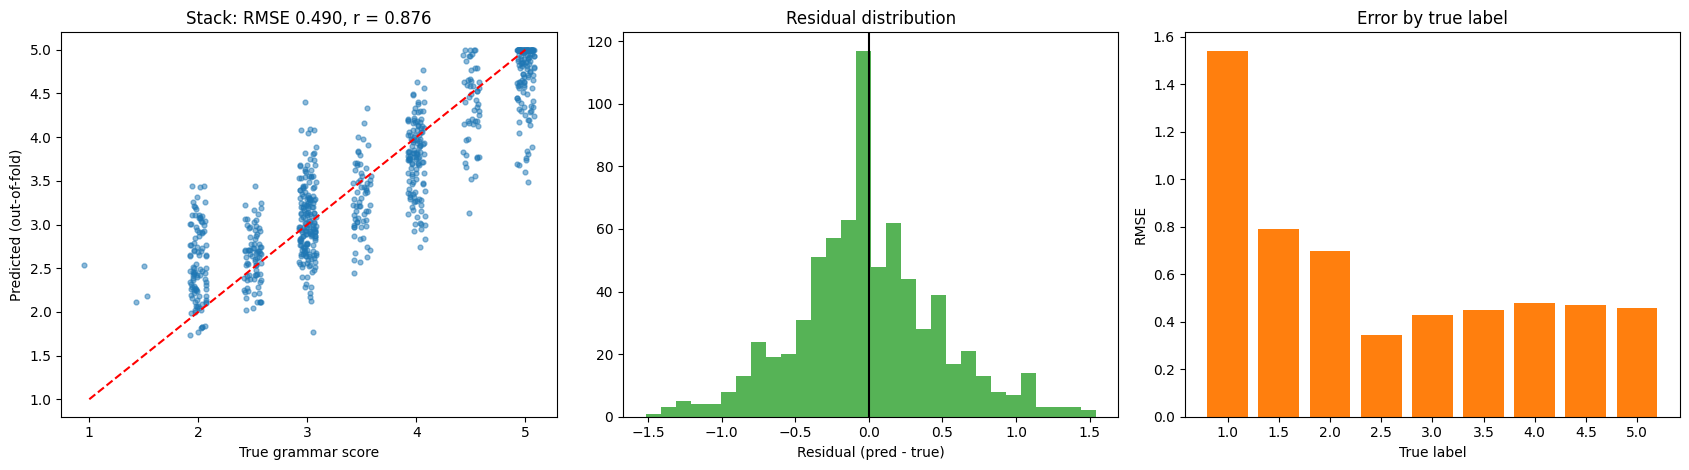

            model  OOF RMSE  Pearson
  ridge_wavlm_cat    0.5200   0.8585
    svr_wavlm_cat    0.5428   0.8518
ridge_whisper_cat    0.5285   0.8539
  svr_whisper_cat    0.5332   0.8548
ridge_whisper_avg    0.5427   0.8450
       ridge_both    0.5193   0.8604
         ridge_e5    0.7249   0.7010
   hgb_text_feats    0.7504   0.6736

STACK meta-CV  RMSE 0.4899  Pearson 0.8757


In [42]:
import pickle, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import pearsonr

S = pickle.load(open('/kaggle/working/stack_v2.pkl', 'rb'))
OOF, y, names = S['OOF'], S['y'], S['names']
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())

# stack OOF via the same non-negative blend (fit on OOF; for plotting only)
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
O = np.column_stack([OOF[n] for n in names])
cvp = np.clip(cross_val_predict(LinearRegression(positive=True), O, y, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
jit = np.random.RandomState(0).uniform(-0.08, 0.08, len(y))
ax[0].scatter(y + jit, cvp, s=12, alpha=0.5); ax[0].plot([1, 5], [1, 5], 'r--')
ax[0].set(xlabel='True grammar score', ylabel='Predicted (out-of-fold)',
          title=f'Stack: RMSE {rmse(cvp, y):.3f}, r = {pearsonr(cvp, y)[0]:.3f}')
ax[1].hist(cvp - y, bins=30, color='tab:green', alpha=0.8); ax[1].axvline(0, color='k')
ax[1].set(xlabel='Residual (pred - true)', title='Residual distribution')
lv = np.sort(np.unique(y)); er = [rmse(cvp[y == v], y[y == v]) for v in lv]
ax[2].bar([str(v) for v in lv], er, color='tab:orange')
ax[2].set(xlabel='True label', ylabel='RMSE', title='Error by true label')
plt.tight_layout(); plt.savefig('/kaggle/working/results.png', dpi=130); plt.show()

res = pd.DataFrame({'model': names, 'OOF RMSE': [rmse(OOF[n], y) for n in names],
                    'Pearson': [pearsonr(OOF[n], y)[0] for n in names]}).round(4)
print(res.to_string(index=False))
print(f"\nSTACK meta-CV  RMSE {rmse(cvp, y):.4f}  Pearson {pearsonr(cvp, y)[0]:.4f}")

In [43]:
import pickle, numpy as np, pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold, cross_val_predict
from scipy.stats import pearsonr

S = pickle.load(open('/kaggle/working/stack_v2.pkl', 'rb'))
OOF, y, names = S['OOF'], S['y'], S['names']
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())
O = np.column_stack([OOF[n] for n in names])
cvp = np.clip(cross_val_predict(LinearRegression(positive=True), O, y,
                                cv=KFold(5, shuffle=True, random_state=1)), 1, 5)

# 1) Is the stack shrinking the extremes toward the middle?
g = pd.DataFrame({'y': y, 'p': cvp})
tab = g.groupby('y').agg(n=('p', 'size'), mean_pred=('p', 'mean'),
                         rmse=('p', lambda s: 0)).round(3)
tab['rmse'] = [rmse(cvp[y == v], y[y == v]) for v in tab.index]
tab['bias'] = tab.mean_pred - tab.index.values
print(tab.round(3).to_string())

# 2) Calibration: slope of true-on-pred (1.0 = well calibrated; >1 = predictions too shrunk)
lr = LinearRegression().fit(cvp[:, None], y)
print(f"\ncalibration slope {lr.coef_[0]:.3f}, intercept {lr.intercept_:.3f}")

# 3) Honest test of recalibration: fit it inside CV on the stack's OOF predictions
kf = KFold(5, shuffle=True, random_state=7)
lin = np.zeros(len(y)); iso = np.zeros(len(y))
for a, b in kf.split(cvp):
    lin[b] = LinearRegression().fit(cvp[a, None], y[a]).predict(cvp[b, None])
    iso[b] = IsotonicRegression(y_min=1, y_max=5, out_of_bounds='clip').fit(cvp[a], y[a]).predict(cvp[b])
for tag, p in [('no recalibration', cvp), ('linear recalibration', np.clip(lin, 1, 5)),
               ('isotonic recalibration', iso)]:
    print(f"{tag:24s} RMSE {rmse(p, y):.4f}  Pearson {pearsonr(p, y)[0]:.4f}")

       n  mean_pred   rmse   bias
y                                
1.0    1      2.542  1.542  1.542
1.5    3      2.272  0.792  0.772
2.0  102      2.552  0.698  0.552
2.5   79      2.632  0.343  0.132
3.0  174      3.051  0.426  0.051
3.5   64      3.298  0.449 -0.202
4.0  124      3.766  0.478 -0.234
4.5   52      4.360  0.471 -0.140
5.0  133      4.723  0.460 -0.277

calibration slope 1.017, intercept -0.050
no recalibration         RMSE 0.4899  Pearson 0.8757
linear recalibration     RMSE 0.4897  Pearson 0.8756
isotonic recalibration   RMSE 0.4873  Pearson 0.8770


In [44]:
%%writefile /kaggle/working/multi_worker.py
import sys, gc, pickle, numpy as np, pandas as pd, soundfile as sf, torch
from transformers import AutoFeatureExtractor, AutoModel
gpu, n = int(sys.argv[1]), int(sys.argv[2])
DATA = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
tr = pd.read_csv(f'{DATA}/train.csv'); tr['split'] = 'train'
te = pd.read_csv(f'{DATA}/test.csv');  te['split'] = 'test'
sub = pd.concat([tr, te], ignore_index=True).iloc[gpu::n]
items = list(zip(sub['split'], sub['filename']))
dev = f'cuda:{gpu}'
MODELS = {'hubert': 'facebook/hubert-large-ll60k',
          'xlsr300': 'facebook/wav2vec2-xls-r-300m',
          'xlsr53': 'facebook/wav2vec2-large-xlsr-53'}
for tag, name in MODELS.items():
    try:
        fe = AutoFeatureExtractor.from_pretrained(name)
        m = AutoModel.from_pretrained(name).half().to(dev).eval()
        out = {}
        for i, k in enumerate(items):
            x, sr = sf.read(f'{DATA}/{k[0]}/{k[1]}', dtype='float32')
            if x.ndim > 1: x = x.mean(1)
            inp = fe(x, sampling_rate=16000, return_tensors='pt').input_values.to(dev).half()
            with torch.no_grad():
                hs = torch.stack(m(inp, output_hidden_states=True).hidden_states)[:, 0].float()
            out[k] = np.concatenate([hs.mean(1).cpu().numpy(), hs.std(1).cpu().numpy()]).astype(np.float16)
            if i % 100 == 0: print(f'GPU{gpu} {tag}: {i}/{len(items)}', flush=True)
        pickle.dump(out, open(f'/kaggle/working/multi_{tag}_{gpu}.pkl', 'wb'))
        print(f'GPU{gpu} {tag}: DONE', flush=True)
        del m, out; gc.collect(); torch.cuda.empty_cache()
    except Exception as e:
        print(f'GPU{gpu} {tag}: FAILED {repr(e)[:300]}', flush=True)
print(f'GPU{gpu}: FINISHED', flush=True)

Writing /kaggle/working/multi_worker.py


In [45]:
import subprocess
procs = [subprocess.Popen(['python', '/kaggle/working/multi_worker.py', str(g), '2'],
                          stdout=open(f'/kaggle/working/mlog{g}.txt', 'w'),
                          stderr=subprocess.STDOUT) for g in (0, 1)]
print("launched")

launched


In [47]:
import subprocess
for g in (0, 1):
    print(subprocess.run(f"grep -E 'GPU{g}' /kaggle/working/mlog{g}.txt | tail -n 3",
                         shell=True, capture_output=True, text=True).stdout)

GPU0 xlsr53: 400/493
GPU0 xlsr53: DONE
GPU0: FINISHED

GPU1 xlsr53: 400/492
GPU1 xlsr53: DONE
GPU1: FINISHED



In [48]:
import subprocess
for g in (0, 1):
    print(subprocess.run(f"grep -E 'DONE|FAILED' /kaggle/working/mlog{g}.txt",
                         shell=True, capture_output=True, text=True).stdout)

GPU0 hubert: DONE
GPU0 xlsr300: DONE
GPU0 xlsr53: DONE

GPU1 hubert: DONE
GPU1 xlsr300: DONE
GPU1 xlsr53: DONE



In [49]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

df = pd.read_pickle('/kaggle/working/alldf.pkl'); keys = list(zip(df.split, df.filename))
tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
y = df.label.values[tr_idx]
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())
rid = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=[1000, 3000, 10000, 30000, 100000]))

def cvfit(mk, X):
    oof = np.zeros(len(y))
    for a, b in folds:
        oof[b] = mk().fit(X[tr_idx[a]], y[a]).predict(X[tr_idx[b]])
    return np.clip(oof, 1, 5)

S = pickle.load(open('/kaggle/working/stack_v2.pkl', 'rb'))
OOF = dict(S['OOF']); ALL = dict(S['ALL'])
base = ['ridge_wavlm_cat', 'svr_wavlm_cat', 'svr_whisper_cat', 'ridge_e5', 'hgb_text_feats']
new = []

for tag in ['hubert', 'xlsr300', 'xlsr53']:
    d = {}
    try:
        for g in (0, 1): d.update(pickle.load(open(f'/kaggle/working/multi_{tag}_{g}.pkl', 'rb')))
    except Exception as e:
        print(tag, 'skipped:', repr(e)[:120]); continue
    Z = np.stack([d[k] for k in keys]).astype(np.float32)          # (985, 2*nl, 1024)
    nl = Z.shape[1] // 2
    lay = lambda ls: np.concatenate([np.concatenate([Z[:, l], Z[:, nl + l]], 1) for l in ls], 1)
    sw = []
    for L in range(nl):
        o = cvfit(rid, lay([L])); sw.append((rmse(o, y), L))
    sw.sort(); top = sorted(l for _, l in sw[:4])
    print(f"{tag}: best layers {[(l, round(r, 4)) for r, l in sw[:4]]}", flush=True)
    X = lay(top)
    for nm, mk in [(f'ridge_{tag}', rid), (f'svr_{tag}', lambda: make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.2)))]:
        OOF[nm] = cvfit(mk, X); ALL[nm] = np.clip(mk().fit(X[tr_idx], y).predict(X), 1, 5)
        new.append(nm)
        print(f"  {nm:16s} OOF RMSE {rmse(OOF[nm], y):.4f}  Pearson {pearsonr(OOF[nm], y)[0]:.4f}", flush=True)
    del Z

def blend(names, tag):
    O = np.column_stack([OOF[n] for n in names])
    cvp = np.clip(cross_val_predict(LinearRegression(positive=True), O, y, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)
    print(f"{tag:32s} meta-CV RMSE {rmse(cvp, y):.4f}  Pearson {pearsonr(cvp, y)[0]:.4f}")
    return cvp
print("\n[control 0.4896 / 0.8758]")
blend(base, 'control')
blend(base + new, 'control + all new backbones')
for t in ['hubert', 'xlsr300', 'xlsr53']:
    ex = [n for n in new if n.endswith(t)]
    if ex: blend(base + ex, f'control + {t}')
pickle.dump(dict(OOF=OOF, ALL=ALL, y=y, new=new, base=base), open('/kaggle/working/stack_v4.pkl', 'wb'))

hubert: best layers [(14, np.float64(0.5694)), (15, np.float64(0.572)), (13, np.float64(0.5732)), (16, np.float64(0.5755))]
  ridge_hubert     OOF RMSE 0.5599  Pearson 0.8341
  svr_hubert       OOF RMSE 0.5556  Pearson 0.8404
xlsr300: best layers [(14, np.float64(0.5956)), (13, np.float64(0.5965)), (12, np.float64(0.5989)), (8, np.float64(0.6016))]
  ridge_xlsr300    OOF RMSE 0.5843  Pearson 0.8172
  svr_xlsr300      OOF RMSE 0.5855  Pearson 0.8234
xlsr53: best layers [(13, np.float64(0.5852)), (12, np.float64(0.5863)), (14, np.float64(0.5915)), (15, np.float64(0.5925))]
  ridge_xlsr53     OOF RMSE 0.5826  Pearson 0.8187
  svr_xlsr53       OOF RMSE 0.5694  Pearson 0.8352

[control 0.4896 / 0.8758]
control                          meta-CV RMSE 0.4896  Pearson 0.8758
control + all new backbones      meta-CV RMSE 0.4902  Pearson 0.8755
control + hubert                 meta-CV RMSE 0.4899  Pearson 0.8757
control + xlsr300                meta-CV RMSE 0.4898  Pearson 0.8757
control + xlsr53 

In [50]:
import re, difflib, pickle, numpy as np, pandas as pd, torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

df = pd.read_pickle('/kaggle/working/alldf.pkl')
name = 'pszemraj/flan-t5-large-grammar-synthesis'
tok = AutoTokenizer.from_pretrained(name)
mdl = AutoModelForSeq2SeqLM.from_pretrained(name).to('cuda:0').eval()   # fp32: T5 overflows in fp16 on T4

def chunk(text, max_words=45):
    sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+', text) if s.strip()]
    out, cur = [], []
    for s in sents:
        if cur and len(' '.join(cur + [s]).split()) > max_words: out.append(' '.join(cur)); cur = []
        cur.append(s)
    if cur: out.append(' '.join(cur))
    return out or [text]

chunks, owner = [], []
for i, t in enumerate(df.text):
    for c in chunk(t): chunks.append(c); owner.append(i)
print(len(chunks), "chunks", flush=True)

order = np.argsort([len(c) for c in chunks]); fixed = [None] * len(chunks)
for s in range(0, len(order), 24):
    idx = order[s:s + 24]
    b = tok([chunks[j] for j in idx], return_tensors='pt', padding=True, truncation=True, max_length=160).to('cuda:0')
    with torch.no_grad():
        o = mdl.generate(**b, max_new_tokens=160, num_beams=1, do_sample=False)
    for j, t in zip(idx, tok.batch_decode(o, skip_special_tokens=True)): fixed[j] = t
    if (s // 24) % 20 == 0: print(f'{s}/{len(order)}', flush=True)

norm = lambda s: re.findall(r"[a-z']+", s.lower())
rows = []
for i in range(len(df)):
    cs = [k for k, o in enumerate(owner) if o == i] if False else None
by_doc = {}
for k, o in enumerate(owner): by_doc.setdefault(o, []).append(k)
for i in range(len(df)):
    src = [w for k in by_doc[i] for w in norm(chunks[k])]
    dst = [w for k in by_doc[i] for w in norm(fixed[k])]
    sm = difflib.SequenceMatcher(None, src, dst, autojunk=False)
    rep = ins = dele = 0
    for tag, a0, a1, b0, b1 in sm.get_opcodes():
        if tag == 'replace': rep += max(a1 - a0, b1 - b0)
        elif tag == 'insert': ins += b1 - b0
        elif tag == 'delete': dele += a1 - a0
    n = max(len(src), 1)
    changed = np.mean([norm(chunks[k]) != norm(fixed[k]) for k in by_doc[i]])
    rows.append(dict(g_ratio=sm.ratio(), g_rep=rep / n, g_ins=ins / n, g_del=dele / n,
                     g_edits=(rep + ins + dele) / n, g_changed=changed, g_len_ratio=len(dst) / n))
G = pd.DataFrame(rows); G.to_pickle('/kaggle/working/gec_feats.pkl')
pd.DataFrame({'text': chunks, 'fixed': fixed}).to_pickle('/kaggle/working/gec_text.pkl')
print(G.describe().T[['mean', 'std']].round(3))
t = df.label.values; m = ((df.split == 'train') & (df.label > 0)).values
print("\nCorrelation with label (train, non-zero):")
print(pd.Series({c: np.corrcoef(G[c].values[m], t[m])[0, 1] for c in G}).round(3).to_string())

config.json:   0%|          | 0.00/892 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.56k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

1920/2579


[transformers] Both `max_new_tokens` (=160) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=160) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=160) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=160) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

2400/2579


[transformers] Both `max_new_tokens` (=160) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=160) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=160) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=160) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

              mean    std
g_ratio      0.870  0.105
g_rep        0.118  0.120
g_ins        0.031  0.041
g_del        0.040  0.050
g_edits      0.189  0.167
g_changed    0.880  0.207
g_len_ratio  0.988  0.065

Correlation with label (train, non-zero):
g_ratio        0.264
g_rep         -0.216
g_ins         -0.152
g_del         -0.197
g_edits       -0.248
g_changed     -0.180
g_len_ratio    0.071


In [51]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import pearsonr

df = pd.read_pickle('/kaggle/working/alldf.pkl')
F = pd.read_pickle('/kaggle/working/feats.pkl'); G = pd.read_pickle('/kaggle/working/gec_feats.pkl')
FG = np.concatenate([F.values, G.values], 1)
tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
y = df.label.values[tr_idx]
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())
hgb = lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.04, max_iter=300, random_state=0)

S = pickle.load(open('/kaggle/working/stack_v4.pkl', 'rb')); OOF, ALL = dict(S['OOF']), dict(S['ALL'])
for nm, X in [('hgb_gec_only', G.values), ('hgb_text+gec', FG)]:
    oof = np.zeros(len(y))
    for a, b in folds: oof[b] = hgb().fit(X[tr_idx[a]], y[a]).predict(X[tr_idx[b]])
    OOF[nm] = np.clip(oof, 1, 5); ALL[nm] = np.clip(hgb().fit(X[tr_idx], y).predict(X), 1, 5)
    print(f"{nm:14s} OOF RMSE {rmse(OOF[nm], y):.4f}  Pearson {pearsonr(OOF[nm], y)[0]:.4f}")

def blend(names, tag):
    O = np.column_stack([OOF[n] for n in names])
    c = np.clip(cross_val_predict(LinearRegression(positive=True), O, y, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)
    print(f"{tag:30s} meta-CV RMSE {rmse(c, y):.4f}  Pearson {pearsonr(c, y)[0]:.4f}")
base = ['ridge_wavlm_cat', 'svr_wavlm_cat', 'svr_whisper_cat', 'ridge_e5', 'hgb_text_feats']
print("\n[control 0.4896 / 0.8758]")
blend(base, 'control')
blend(base + ['hgb_gec_only'], '+ gec_only')
blend(base[:-1] + ['hgb_text+gec'], 'text+gec replaces text')
pickle.dump(dict(OOF=OOF, ALL=ALL, y=y), open('/kaggle/working/stack_v5.pkl', 'wb'))

hgb_gec_only   OOF RMSE 1.0011  Pearson 0.2604
hgb_text+gec   OOF RMSE 0.7517  Pearson 0.6722

[control 0.4896 / 0.8758]
control                        meta-CV RMSE 0.4896  Pearson 0.8758
+ gec_only                     meta-CV RMSE 0.4897  Pearson 0.8757
text+gec replaces text         meta-CV RMSE 0.4891  Pearson 0.8761


In [52]:
import subprocess
print(subprocess.run("pip install -q peft 2>&1 | tail -n 2", shell=True, capture_output=True, text=True).stdout)

import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
S = pickle.load(open('/kaggle/working/stack_v2.pkl', 'rb'))
df = pd.read_pickle('/kaggle/working/alldf.pkl')
tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
y = df.label.values[tr_idx]
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
a, b = folds[0]
rmse = lambda p, t: np.sqrt(((p - t) ** 2).mean())
for n in ['ridge_wavlm_cat', 'svr_whisper_cat']:
    print(f"fold-0 reference {n}: RMSE {rmse(S['OOF'][n][b], y[b]):.4f}")
print("fold sizes:", len(a), len(b))


fold-0 reference ridge_wavlm_cat: RMSE 0.5705
fold-0 reference svr_whisper_cat: RMSE 0.5730
fold sizes: 585 147


In [53]:
%%writefile /kaggle/working/lora_worker.py
import sys, pickle, time, numpy as np, pandas as pd, soundfile as sf, torch, torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from transformers import WavLMModel
from peft import LoraConfig, get_peft_model

fold, gpu = int(sys.argv[1]), int(sys.argv[2])
EPOCHS, LR, BS_ACC = 6, 2e-4, 4
DATA = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
dev = f'cuda:{gpu}'
tr = pd.read_csv(f'{DATA}/train.csv'); tr['split'] = 'train'
te = pd.read_csv(f'{DATA}/test.csv');  te['split'] = 'test'
df = pd.concat([tr, te], ignore_index=True)
tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
te_idx = np.where((df.split == 'test').values)[0]
y = df.label.values[tr_idx].astype(np.float32); mu, sd = y.mean(), y.std()
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
a, b = folds[fold]

def load(i):
    x, _ = sf.read(f'{DATA}/{df.split[i]}/{df.filename[i]}', dtype='float32')
    if x.ndim > 1: x = x.mean(1)
    return (x - x.mean()) / (x.std() + 1e-7)
cache = {}
def get(i):
    if i not in cache: cache[i] = load(i)
    return cache[i]

class Net(nn.Module):
    def __init__(s):
        super().__init__()
        base = WavLMModel.from_pretrained('microsoft/wavlm-large')
        base.config.mask_time_prob = 0.05
        base.freeze_feature_encoder()
        cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.1,
                         target_modules=[f'encoder.layers.{l}.attention.{p}' for l in range(12, 24)
                                         for p in ('q_proj', 'k_proj', 'v_proj', 'out_proj')])
        s.m = get_peft_model(base, cfg)
        s.m.base_model.model.gradient_checkpointing_enable()
        s.att = nn.Linear(1024, 1); s.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(1024, 1))
    def forward(s, x):
        h = s.m(x).last_hidden_state
        w = torch.softmax(s.att(h), 1)
        return s.head((w * h).sum(1)).squeeze(-1)

torch.manual_seed(fold); np.random.seed(fold)
net = Net().to(dev)
params = [p for p in net.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.01)
steps = EPOCHS * int(np.ceil(len(a) / BS_ACC))
sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.15)
scaler = torch.amp.GradScaler()

def predict(idx):
    net.eval(); out = []
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for i in idx:
            out.append(net(torch.tensor(get(i))[None].to(dev)).float().item())
    return np.array(out) * sd + mu

t0 = time.time()
for ep in range(EPOCHS):
    net.train(); perm = np.random.permutation(len(a)); tl = 0
    for j in range(0, len(perm), BS_ACC):
        opt.zero_grad()
        for k in perm[j:j + BS_ACC]:
            x = get(tr_idx[a[k]])
            L = 30 * 16000
            if len(x) > L:
                s0 = np.random.randint(0, len(x) - L); x = x[s0:s0 + L]
            tgt = torch.tensor((y[a[k]] - mu) / sd).to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                loss = (net(torch.tensor(x)[None].to(dev)).float().squeeze() - tgt) ** 2 / BS_ACC
            scaler.scale(loss).backward(); tl += loss.item()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); sch.step()
    pv = predict(tr_idx[b])
    r = np.sqrt(((np.clip(pv, 1, 5) - y[b]) ** 2).mean())
    print(f'FOLD{fold} epoch {ep+1}/{EPOCHS}  train_loss {tl/(len(perm)/BS_ACC):.3f}  val RMSE {r:.4f}  ({(time.time()-t0)/60:.1f} min)', flush=True)

pv = np.clip(predict(tr_idx[b]), 1, 5); pt = np.clip(predict(te_idx), 1, 5)
pickle.dump(dict(val_idx=b, val=pv, test=pt), open(f'/kaggle/working/lora_fold{fold}.pkl', 'wb'))
print(f'FOLD{fold}: FINISHED', flush=True)

Writing /kaggle/working/lora_worker.py


In [54]:
import subprocess
p = subprocess.Popen(['python', '/kaggle/working/lora_worker.py', '0', '0'],
                     stdout=open('/kaggle/working/llog0.txt', 'w'), stderr=subprocess.STDOUT)
print("launched")

launched


In [55]:
import subprocess
print(subprocess.run("grep -E 'FOLD|Error|error|Traceback' /kaggle/working/llog0.txt | tail -n 8",
                     shell=True, capture_output=True, text=True).stdout)

Traceback (most recent call last):
    raise ImportError(
ImportError: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported



In [56]:
import subprocess
print(subprocess.run("pip uninstall -y torchao 2>&1 | tail -n 2", shell=True, capture_output=True, text=True).stdout)
print(subprocess.run(["python", "-c", "import peft, transformers; print('peft', peft.__version__, 'OK')"],
                     capture_output=True, text=True))

Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0

CompletedProcess(args=['python', '-c', "import peft, transformers; print('peft', peft.__version__, 'OK')"], returncode=0, stdout='peft 0.20.0 OK\n', stderr='')


In [57]:
import subprocess
p = subprocess.Popen(['python', '/kaggle/working/lora_worker.py', '0', '0'],
                     stdout=open('/kaggle/working/llog0.txt', 'w'), stderr=subprocess.STDOUT)
print("launched")

launched


In [63]:
import subprocess
print(subprocess.run("grep -E 'FOLD|Error|error|Traceback' /kaggle/working/llog0.txt | tail -n 8",
                     shell=True, capture_output=True, text=True).stdout)

FOLD0 epoch 1/6  train_loss 0.985  val RMSE 1.0042  (7.2 min)
FOLD0 epoch 2/6  train_loss 0.926  val RMSE 0.9772  (14.1 min)
FOLD0 epoch 3/6  train_loss 0.876  val RMSE 0.9579  (21.0 min)
FOLD0 epoch 4/6  train_loss 0.838  val RMSE 0.9491  (27.9 min)



In [64]:
p.kill(); print("killed")

killed


In [65]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
S = pickle.load(open('/kaggle/working/stack_v2.pkl', 'rb'))
df = pd.read_pickle('/kaggle/working/alldf.pkl')
tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
y = df.label.values[tr_idx]
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
rmse = lambda p, t: np.sqrt(((p - t) ** 2).mean())
for f in (0, 1):
    b = folds[f][1]
    for n in ['ridge_wavlm_cat', 'svr_whisper_cat']:
        print(f"fold {f} reference {n}: RMSE {rmse(S['OOF'][n][b], y[b]):.4f}")

fold 0 reference ridge_wavlm_cat: RMSE 0.5705
fold 0 reference svr_whisper_cat: RMSE 0.5730
fold 1 reference ridge_wavlm_cat: RMSE 0.5571
fold 1 reference svr_whisper_cat: RMSE 0.5386


In [66]:
%%writefile /kaggle/working/lora_worker2.py
import sys, pickle, time, numpy as np, pandas as pd, soundfile as sf, torch, torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from transformers import WavLMModel
from peft import LoraConfig, get_peft_model

fold, gpu = int(sys.argv[1]), int(sys.argv[2])
EPOCHS, LR_LORA, LR_HEAD, BS_ACC, KEEP = 8, 3e-4, 1e-3, 4, 18
DATA = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
dev = f'cuda:{gpu}'
tr = pd.read_csv(f'{DATA}/train.csv'); tr['split'] = 'train'
te = pd.read_csv(f'{DATA}/test.csv');  te['split'] = 'test'
df = pd.concat([tr, te], ignore_index=True)
tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
te_idx = np.where((df.split == 'test').values)[0]
y = df.label.values[tr_idx].astype(np.float32); mu, sd = y.mean(), y.std()
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
a, b = folds[fold]

cache = {}
def get(i):
    if i not in cache:
        x, _ = sf.read(f'{DATA}/{df.split[i]}/{df.filename[i]}', dtype='float32')
        if x.ndim > 1: x = x.mean(1)
        cache[i] = (x - x.mean()) / (x.std() + 1e-7)
    return cache[i]

class Net(nn.Module):
    def __init__(s):
        super().__init__()
        base = WavLMModel.from_pretrained('microsoft/wavlm-large')
        base.config.mask_time_prob = 0.05
        base.config.layerdrop = 0.0
        base.freeze_feature_encoder()
        base.encoder.layers = base.encoder.layers[:KEEP]          # keep layers 0..17 only
        cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.1,
                         target_modules=[f'encoder.layers.{l}.attention.{p}' for l in range(6, KEEP)
                                         for p in ('q_proj', 'k_proj', 'v_proj', 'out_proj')])
        s.m = get_peft_model(base, cfg)
        s.norm = nn.LayerNorm(2048)
        s.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(2048, 1))
    def forward(s, x):
        h = s.m(x).last_hidden_state                                # (1, T, 1024)
        z = torch.cat([h.mean(1), h.std(1)], 1).float()
        return s.head(s.norm(z)).squeeze(-1)

torch.manual_seed(fold); np.random.seed(fold)
net = Net().to(dev)
lora_p = [p for n, p in net.named_parameters() if p.requires_grad and 'lora_' in n]
head_p = [p for n, p in net.named_parameters() if p.requires_grad and 'lora_' not in n]
print(f'FOLD{fold}: trainable lora tensors {len(lora_p)}, head tensors {len(head_p)}', flush=True)
opt = torch.optim.AdamW([{'params': lora_p, 'lr': LR_LORA}, {'params': head_p, 'lr': LR_HEAD}], weight_decay=0.01)
steps = EPOCHS * int(np.ceil(len(a) / BS_ACC))
sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_LORA, LR_HEAD], total_steps=steps, pct_start=0.15)
scaler = torch.amp.GradScaler()

def predict(idx):
    net.eval(); out = []
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for i in idx:
            out.append(net(torch.tensor(get(i))[None].to(dev)).float().item())
    return np.array(out) * sd + mu

t0, first = time.time(), True
for ep in range(EPOCHS):
    net.train(); perm = np.random.permutation(len(a)); tl = 0
    for j in range(0, len(perm), BS_ACC):
        opt.zero_grad()
        for k in perm[j:j + BS_ACC]:
            x = get(tr_idx[a[k]]); L = 30 * 16000
            if len(x) > L:
                s0 = np.random.randint(0, len(x) - L); x = x[s0:s0 + L]
            tgt = torch.tensor((y[a[k]] - mu) / sd).to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                loss = (net(torch.tensor(x)[None].to(dev)).float().squeeze() - tgt) ** 2 / BS_ACC
            scaler.scale(loss).backward(); tl += loss.item()
        if first:
            nz = sum(p.grad is not None and p.grad.abs().sum().item() > 0 for p in lora_p)
            print(f'FOLD{fold} GRADCHECK: {nz}/{len(lora_p)} LoRA tensors received gradient', flush=True); first = False
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(lora_p + head_p, 1.0)
        scaler.step(opt); scaler.update(); sch.step()
    pv = predict(tr_idx[b])
    r = np.sqrt(((np.clip(pv, 1, 5) - y[b]) ** 2).mean())
    print(f'FOLD{fold} epoch {ep+1}/{EPOCHS}  train_loss {tl/(len(perm)/BS_ACC):.3f}  val RMSE {r:.4f}  ({(time.time()-t0)/60:.1f} min)', flush=True)

pv = np.clip(predict(tr_idx[b]), 1, 5); pt = np.clip(predict(te_idx), 1, 5)
pickle.dump(dict(val_idx=b, val=pv, test=pt), open(f'/kaggle/working/lora2_fold{fold}.pkl', 'wb'))
print(f'FOLD{fold}: FINISHED', flush=True)

Writing /kaggle/working/lora_worker2.py


In [70]:
import subprocess
print(subprocess.run(['nvidia-smi', '--query-gpu=memory.used', '--format=csv'], capture_output=True, text=True).stdout)
procs = [subprocess.Popen(['python', '/kaggle/working/lora_worker2.py', str(f), str(f)],
                          stdout=open(f'/kaggle/working/l2log{f}.txt', 'w'), stderr=subprocess.STDOUT) for f in (0, 1)]
print("launched fold 0 on GPU0 and fold 1 on GPU1")

memory.used [MiB]
6413 MiB
3 MiB

launched fold 0 on GPU0 and fold 1 on GPU1


In [87]:
import subprocess
for f in (0, 1):
    print(subprocess.run(f"grep -E 'FOLD|Error|error|Traceback' /kaggle/working/l2log{f}.txt | tail -n 6",
                         shell=True, capture_output=True, text=True).stdout)

FOLD0 epoch 4/8  train_loss 0.681  val RMSE 0.7222  (25.5 min)
FOLD0 epoch 5/8  train_loss 0.644  val RMSE 0.6527  (31.8 min)
FOLD0 epoch 6/8  train_loss 0.473  val RMSE 0.6827  (38.1 min)
FOLD0 epoch 7/8  train_loss 0.415  val RMSE 0.6532  (44.3 min)
FOLD0 epoch 8/8  train_loss 0.425  val RMSE 0.6839  (50.6 min)
FOLD0: FINISHED

FOLD1 epoch 4/8  train_loss 0.596  val RMSE 0.7286  (25.5 min)
FOLD1 epoch 5/8  train_loss 0.459  val RMSE 0.6331  (31.8 min)
FOLD1 epoch 6/8  train_loss 0.461  val RMSE 0.7454  (38.0 min)
FOLD1 epoch 7/8  train_loss 0.440  val RMSE 0.5984  (44.3 min)
FOLD1 epoch 8/8  train_loss 0.427  val RMSE 0.6010  (50.6 min)
FOLD1: FINISHED



In [88]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LinearRegression
S = pickle.load(open('/kaggle/working/stack_v2.pkl', 'rb'))
df = pd.read_pickle('/kaggle/working/alldf.pkl')
tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
y = df.label.values[tr_idx]
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr_idx, np.digitize(y, [2.25, 3.25, 4.25])))
rmse = lambda p, t: np.sqrt(((p - t) ** 2).mean())
L = {f: pickle.load(open(f'/kaggle/working/lora2_fold{f}.pkl', 'rb')) for f in (0, 1)}
vi = np.concatenate([folds[f][1] for f in (0, 1)])
lo = np.concatenate([L[f]['val'] for f in (0, 1)]); yy = y[vi]
for n in ['ridge_wavlm_cat', 'svr_whisper_cat']:
    print(f"{n:18s} on folds 0+1: {rmse(S['OOF'][n][vi], yy):.4f}")
print(f"{'lora':18s} on folds 0+1: {rmse(lo, yy):.4f}")
base = np.column_stack([S['OOF'][n][vi] for n in ['ridge_wavlm_cat', 'svr_whisper_cat', 'ridge_e5']])
from sklearn.model_selection import KFold, cross_val_predict
for tag, O in [('blend without lora', base), ('blend with lora', np.column_stack([base, lo]))]:
    c = np.clip(cross_val_predict(LinearRegression(positive=True), O, yy, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)
    print(f"{tag:22s} RMSE {rmse(c, yy):.4f}")

ridge_wavlm_cat    on folds 0+1: 0.5638
svr_whisper_cat    on folds 0+1: 0.5561
lora               on folds 0+1: 0.6438
blend without lora     RMSE 0.5397
blend with lora        RMSE 0.5421


In [89]:
import pandas as pd
a = pd.read_csv('/kaggle/working/submission.csv')
b = pd.read_csv('/kaggle/working/submission_v2.csv')
assert (a.filename == b.filename).all()
a['label'] = ((a.label + b.label) / 2).clip(1, 5)
a.to_csv('/kaggle/working/submission_avg.csv', index=False)
print(a.shape, a.label.describe().round(3).to_dict())

(216, 2) {'count': 216.0, 'mean': 3.285, 'std': 0.841, 'min': 1.798, '25%': 2.68, '50%': 3.182, '75%': 3.737, 'max': 5.0}


In [90]:
import pickle, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

df = pd.read_pickle('/kaggle/working/alldf.pkl'); keys = list(zip(df.split, df.filename))
F = pd.read_pickle('/kaggle/working/feats.pkl').values
T = np.load('/kaggle/working/text_emb_e5.npy')
emb, W = {}, {}
for g in (0, 1):
    emb.update(pickle.load(open(f'/kaggle/working/emb_{g}.pkl', 'rb')))
    W.update(pickle.load(open(f'/kaggle/working/wenc_{g}.pkl', 'rb')))
E  = np.stack([emb[k] for k in keys]).astype(np.float32)
WE = np.stack([W[k]   for k in keys]).astype(np.float32)
wl = lambda ls: np.concatenate([np.concatenate([E[:, l],  E[:, 25 + l]],  1) for l in ls], 1)
ws = lambda ls: np.concatenate([np.concatenate([WE[:, l], WE[:, 33 + l]], 1) for l in ls], 1)
XW, XE = wl((8, 14, 18, 21)), ws((20, 24, 28, 31))

tr_idx = np.where(((df.split == 'train') & (df.label > 0)).values)[0]
te_idx = np.where((df.split == 'test').values)[0]
y = df.label.values[tr_idx]; strat = np.digitize(y, [2.25, 3.25, 4.25])
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean())

ridge = lambda a=(1000, 3000, 10000, 30000, 100000): (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=list(a))))
svr   = lambda: make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.2))
hgb   = lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.04, max_iter=300, random_state=0)
models = {'ridge_wavlm_cat': (ridge(), XW), 'svr_wavlm_cat': (svr, XW), 'svr_whisper_cat': (svr, XE),
          'ridge_e5': (ridge((100, 300, 1000, 3000, 10000)), T), 'hgb_text_feats': (hgb, F)}
names = list(models)

test_preds, cv_scores = [], []
for seed in range(5):
    folds = list(StratifiedKFold(5, shuffle=True, random_state=100 + seed).split(tr_idx, strat))
    OOF = {n: np.zeros(len(y)) for n in names}; TP = {n: np.zeros(len(te_idx)) for n in names}
    for a, b in folds:
        for n, (mk, X) in models.items():
            m = mk().fit(X[tr_idx[a]], y[a])
            OOF[n][b] = m.predict(X[tr_idx[b]]); TP[n] += m.predict(X[te_idx]) / len(folds)
    O = np.clip(np.column_stack([OOF[n] for n in names]), 1, 5)
    Pt = np.clip(np.column_stack([TP[n] for n in names]), 1, 5)
    cvp = np.clip(cross_val_predict(LinearRegression(positive=True), O, y, cv=KFold(5, shuffle=True, random_state=1)), 1, 5)
    meta = LinearRegression(positive=True).fit(O, y)
    test_preds.append(np.clip(meta.predict(Pt), 1, 5)); cv_scores.append(rmse(cvp, y))
    print(f"seed {seed}: meta-CV RMSE {cv_scores[-1]:.4f}  weights {meta.coef_.round(2)}", flush=True)

bag = np.mean(test_preds, 0)
print("mean meta-CV over seeds:", round(float(np.mean(cv_scores)), 4), "(single-split reference: 0.4899)")
old = pd.read_csv('/kaggle/working/submission_avg.csv')
assert (old.filename.values == df.filename.values[te_idx]).all()
print("corr(bagged, current avg):", round(pearsonr(bag, old.label)[0], 4),
      "| RMSE between them:", round(rmse(bag, old.label.values), 4))
pd.DataFrame({'filename': old.filename, 'label': bag}).to_csv('/kaggle/working/submission_bag.csv', index=False)
pd.DataFrame({'filename': old.filename, 'label': np.clip((bag + old.label.values) / 2, 1, 5)}).to_csv('/kaggle/working/submission_bag_avg.csv', index=False)
print("saved submission_bag.csv and submission_bag_avg.csv")

seed 0: meta-CV RMSE 0.4863  weights [0.45 0.   0.52 0.14 0.08]
seed 1: meta-CV RMSE 0.4763  weights [0.45 0.03 0.5  0.17 0.05]
seed 2: meta-CV RMSE 0.4891  weights [0.41 0.   0.54 0.16 0.09]
seed 3: meta-CV RMSE 0.4861  weights [0.41 0.13 0.42 0.17 0.09]
seed 4: meta-CV RMSE 0.4839  weights [0.35 0.08 0.52 0.17 0.1 ]
mean meta-CV over seeds: 0.4844 (single-split reference: 0.4899)
corr(bagged, current avg): 0.9961 | RMSE between them: 0.0749
saved submission_bag.csv and submission_bag_avg.csv
